In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

In [2]:
stroke_data = pd.read_csv(
    '..\data\stroke_risk_prediction_dataset.csv')
stroke_data.head()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate


In [3]:
stroke_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    50000 non-null  int64  
 1   Age                           49781 non-null  float64
 2   Gender                        50000 non-null  str    
 3   Country                       50000 non-null  str    
 4   Height_cm                     48475 non-null  float64
 5   Weight_kg                     48477 non-null  float64
 6   BMI                           50000 non-null  float64
 7   Blood_Pressure_Systolic       50000 non-null  int64  
 8   Blood_Pressure_Diastolic      50000 non-null  int64  
 9   Heart_Rate                    50000 non-null  int64  
 10  Blood_Glucose                 49040 non-null  float64
 11  HbA1c                         48994 non-null  float64
 12  Total_Cholesterol             48996 non-null  float64
 13  HDL         

In [4]:
# Check for missing values in the dataset
for column in stroke_data.columns:
    if stroke_data[column].isnull().sum() > 0:
        print(f"Column '{column}' has {stroke_data[column].isnull().sum()} missing values.")

Column 'Age' has 219 missing values.
Column 'Height_cm' has 1525 missing values.
Column 'Weight_kg' has 1523 missing values.
Column 'Blood_Glucose' has 960 missing values.
Column 'HbA1c' has 1006 missing values.
Column 'Total_Cholesterol' has 1004 missing values.
Column 'HDL' has 1021 missing values.
Column 'LDL' has 1050 missing values.
Column 'Triglycerides' has 1032 missing values.
Column 'Sleep_Hours' has 1026 missing values.
Column 'Medication_Adherence' has 1051 missing values.
Column 'Exercise_Hours_Per_Week' has 1054 missing values.
Column 'Daily_Walking_Minutes' has 1051 missing values.


In [5]:
stroke_data.duplicated().sum()

np.int64(0)

In [6]:
stroke_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    50000 non-null  int64  
 1   Age                           49781 non-null  float64
 2   Gender                        50000 non-null  str    
 3   Country                       50000 non-null  str    
 4   Height_cm                     48475 non-null  float64
 5   Weight_kg                     48477 non-null  float64
 6   BMI                           50000 non-null  float64
 7   Blood_Pressure_Systolic       50000 non-null  int64  
 8   Blood_Pressure_Diastolic      50000 non-null  int64  
 9   Heart_Rate                    50000 non-null  int64  
 10  Blood_Glucose                 49040 non-null  float64
 11  HbA1c                         48994 non-null  float64
 12  Total_Cholesterol             48996 non-null  float64
 13  HDL         

In [7]:
# Analysing the dataset columns and their statistics in order to fill the missing values in the dataset
def print_stats(column_name):
    print('Column:', column_name)
    print('Median:',stroke_data[column_name].median())
    print('Mean:', stroke_data[column_name].mean())
    print('Min:', stroke_data[column_name].min())
    print('Max:', stroke_data[column_name].max())
    print('Std:', stroke_data[column_name].std())
    print('CoV:', (stroke_data[column_name].std() / stroke_data[column_name].mean()) * 100)
    CoV = (stroke_data[column_name].std() / stroke_data[column_name].mean()) * 100
    if CoV > 20:
        stroke_data.drop(index=stroke_data[stroke_data[column_name].isnull()].index, inplace=True)
        stroke_data.reset_index(drop=True, inplace=True)
        print(f"Column '{column_name}' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.")
    else:
        stroke_data[column_name].fillna({column_name: stroke_data[column_name].median()}, inplace=True)
        print(f"Column '{column_name}' has a Coefficient of Variation (CoV) less than or equal to 20%. Missing values in this column have been filled with the median.")

In [8]:
# Running the function for each numeric column with missing values
for column in stroke_data.columns:
    if stroke_data[column].isnull().sum() > 0:
        if stroke_data[column].dtype in ['float64', 'int64']:
            print_stats(column)

Column: Age
Median: 54.0
Mean: 53.90309555854643
Min: 18.0
Max: 90.0
Std: 21.070953109559323
CoV: 39.09043236055575
Column 'Age' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.
Column: Height_cm
Median: 170.1
Mean: 170.1266260541638
Min: 145.0
Max: 195.0
Std: 14.481663803629438
CoV: 8.512285313304726
Column 'Height_cm' has a Coefficient of Variation (CoV) less than or equal to 20%. Missing values in this column have been filled with the median.
Column: Weight_kg
Median: 87.5
Mean: 87.51042119874863
Min: 45.0
Max: 130.0
Std: 24.56679208615576
CoV: 28.072990336043606
Column 'Weight_kg' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.
Column: Blood_Glucose
Median: 145.1
Mean: 145.0892501743044
Min: 70.0
Max: 220.0
Std: 43.39067479309805
CoV: 29.906195490686066
Column 'Blood_Glucose' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing value

C:\Users\madki\AppData\Local\Temp\ipykernel_12836\2203831074.py:16: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  stroke_data[column_name].fillna({column_name: stroke_data[column_name].median()}, inplace=True)


Column: LDL
Median: 140.3
Mean: 140.21221181225314
Min: 60.0
Max: 220.0
Std: 46.1366553875367
CoV: 32.90487668029556
Column 'LDL' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.
Column: Triglycerides
Median: 205.4
Mean: 205.2313509837488
Min: 60.0
Max: 350.0
Std: 83.60914582692787
CoV: 40.73897356625034
Column 'Triglycerides' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.
Column: Sleep_Hours
Median: 7.0
Mean: 7.0042765127026305
Min: 4.0
Max: 10.0
Std: 1.732908810945658
CoV: 24.74072529550961
Column 'Sleep_Hours' has a Coefficient of Variation (CoV) greater than 20%. Rows with missing values in this column have been dropped.
Column: Exercise_Hours_Per_Week
Median: 5.0
Mean: 5.011476894458586
Min: 0.0
Max: 10.0
Std: 2.892799515003226
CoV: 57.7234930126471
Column 'Exercise_Hours_Per_Week' has a Coefficient of Variation (CoV) greater than 20%. Rows with missi

In [9]:
stroke_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 40003 entries, 0 to 40002
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    40003 non-null  int64  
 1   Age                           40003 non-null  float64
 2   Gender                        40003 non-null  str    
 3   Country                       40003 non-null  str    
 4   Height_cm                     38773 non-null  float64
 5   Weight_kg                     40003 non-null  float64
 6   BMI                           40003 non-null  float64
 7   Blood_Pressure_Systolic       40003 non-null  int64  
 8   Blood_Pressure_Diastolic      40003 non-null  int64  
 9   Heart_Rate                    40003 non-null  int64  
 10  Blood_Glucose                 40003 non-null  float64
 11  HbA1c                         40003 non-null  float64
 12  Total_Cholesterol             40003 non-null  float64
 13  HDL         

In [10]:
# Filling missing values in categorical columns with 'No data available'
for column in stroke_data.columns:
    if stroke_data[column].isnull().sum() > 0:
        if stroke_data[column].dtype in ['str']:
            stroke_data[column].fillna('No data available', inplace=True)

C:\Users\madki\AppData\Local\Temp\ipykernel_12836\1404594804.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  stroke_data[column].fillna('No data available', inplace=True)


In [11]:
#Checking for missing values in the dataset after filling them
for column in stroke_data.columns:
    if stroke_data[column].isnull().sum() > 0:
        print(f"Column '{column}' has {stroke_data[column].isnull().sum()} missing values.")

Column 'Height_cm' has 1230 missing values.
Column 'Medication_Adherence' has 863 missing values.


In [12]:
stroke_data['Medication_Adherence'].info()

<class 'pandas.Series'>
RangeIndex: 40003 entries, 0 to 40002
Series name: Medication_Adherence
Non-Null Count  Dtype
--------------  -----
39140 non-null  str  
dtypes: str(1)
memory usage: 572.5 KB


In [13]:
stroke_data.fillna({'Medication_Adherence': 'No data available'}, inplace=True)
stroke_data['Medication_Adherence'].isna().sum()  

np.int64(0)

In [14]:
stroke_data.fillna({'Height_cm': stroke_data['Height_cm'].median()}, inplace=True)
stroke_data['Height_cm'].isna().sum()

np.int64(0)

In [15]:
stroke_data['Stroke_Risk'].unique()

<ArrowStringArray>
['High', 'Moderate', 'Low']
Length: 3, dtype: str

Text(0.5, 1.0, 'Distribution of Stroke Risk')

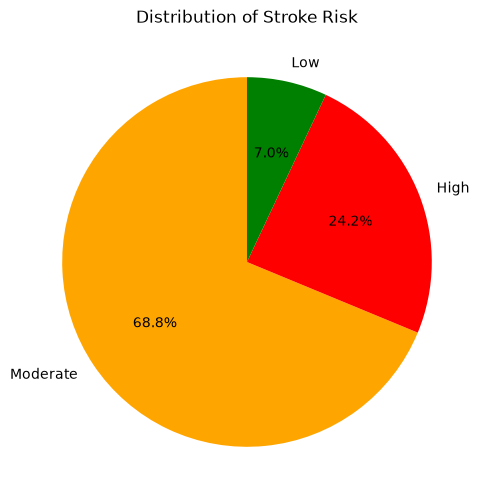

In [16]:
# Visualizing the distribution of Stroke Risk
fig, ax = plt.subplots(figsize=(10, 6))

plt.pie(stroke_data['Stroke_Risk'].value_counts(), labels=stroke_data['Stroke_Risk'].value_counts().index,
         autopct='%1.1f%%', startangle=90, colors=sns.color_palette(['orange', 'red', 'green']))
plt.title('Distribution of Stroke Risk')

In [17]:
# Creating separate DataFrames for each Stroke Risk category
low_risk = stroke_data.query('Stroke_Risk == "Low"')
moderate_risk = stroke_data.query('Stroke_Risk == "Moderate"')
high_risk = stroke_data.query('Stroke_Risk == "High"')

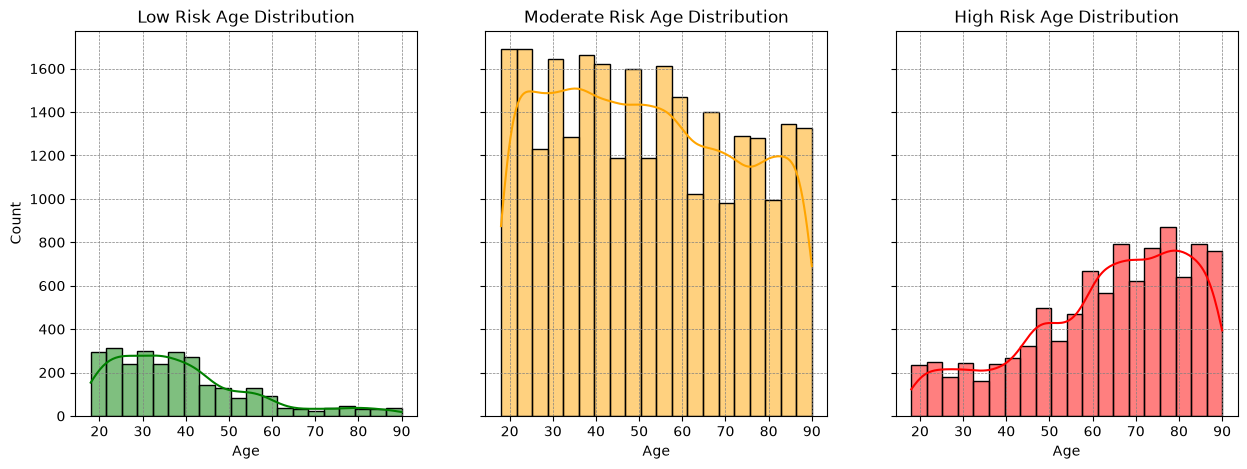

In [18]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
sns.histplot(low_risk['Age'], bins=20, kde=True, color='green', ax=ax)
ax.set_title('Low Risk Age Distribution')
ax.grid(color='gray', linestyle='--', linewidth=0.5)
sns.histplot(moderate_risk['Age'], bins=20, kde=True, ax=bx, color='orange')
bx.set_title('Moderate Risk Age Distribution')
bx.grid(color='gray', linestyle='--', linewidth=0.5)
sns.histplot(high_risk['Age'], bins=20, kde=True, ax=cx, color='red')
cx.set_title('High Risk Age Distribution')
cx.grid(color='gray', linestyle='--', linewidth=0.5)

In [19]:
low_gender = low_risk['Gender'].value_counts()
moderate_gender = moderate_risk['Gender'].value_counts()
high_gender = high_risk['Gender'].value_counts()

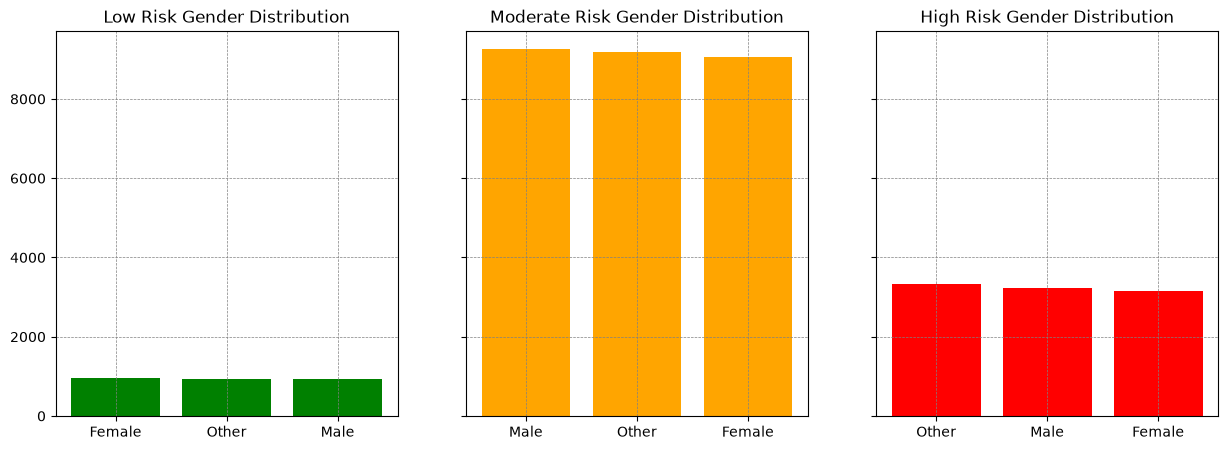

In [20]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
ax.bar(low_gender.index, low_gender.values, color='green')
ax.set_title('Low Risk Gender Distribution')
ax.grid(color='gray', linestyle='--', linewidth=0.5)
bx.bar(moderate_gender.index, moderate_gender.values, color='orange')
bx.set_title('Moderate Risk Gender Distribution')
bx.grid(color='gray', linestyle='--', linewidth=0.5)
cx.bar(high_gender.index, high_gender.values, color='red')
cx.set_title('High Risk Gender Distribution')
cx.grid(color='gray', linestyle='--', linewidth=0.5)

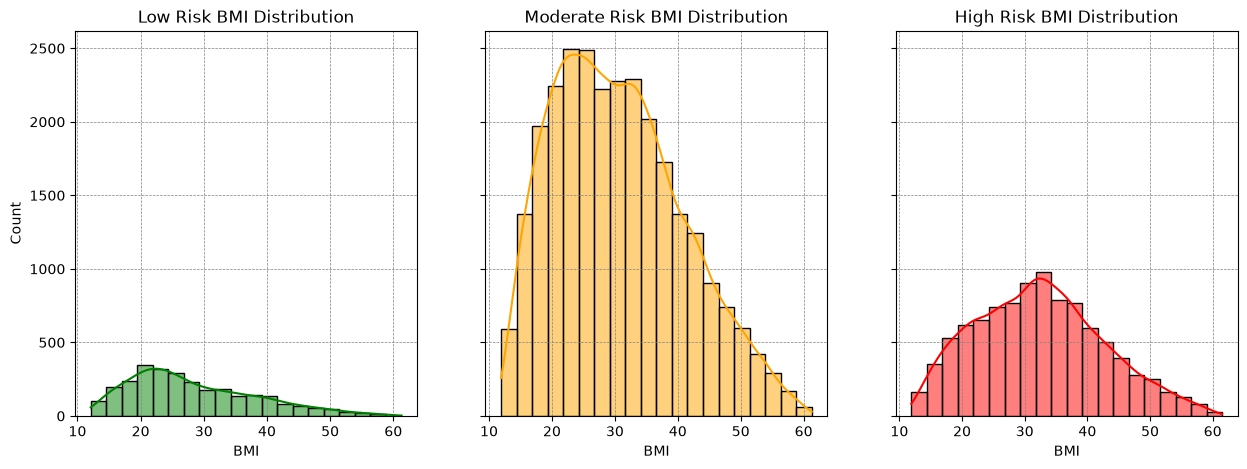

In [21]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
sns.histplot(low_risk['BMI'], bins=20, kde=True, color='green', ax=ax)
ax.set_title('Low Risk BMI Distribution')
ax.grid(color='gray', linestyle='--', linewidth=0.5)
sns.histplot(moderate_risk['BMI'], bins=20, kde=True, ax=bx, color='orange')
bx.set_title('Moderate Risk BMI Distribution')
bx.grid(color='gray', linestyle='--', linewidth=0.5)
sns.histplot(high_risk['BMI'], bins=20, kde=True, ax=cx, color='red')
cx.set_title('High Risk BMI Distribution')
cx.grid(color='gray', linestyle='--', linewidth=0.5)

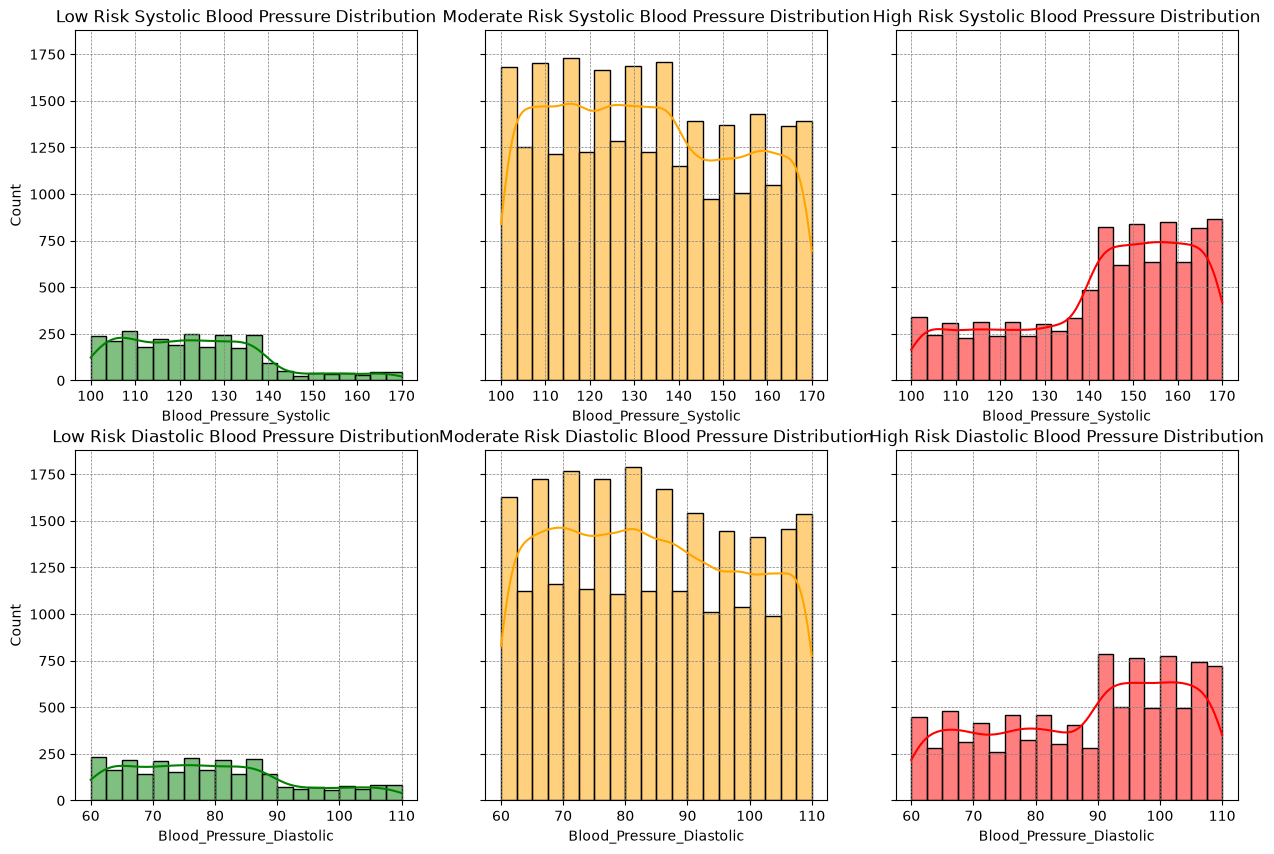

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)

sns.histplot(low_risk['Blood_Pressure_Systolic'], bins=20, kde=True, color='green', ax=axes[0, 0])
axes[0, 0].set_title('Low Risk Systolic Blood Pressure Distribution')
axes[0, 0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['Blood_Pressure_Systolic'], bins=20, kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Moderate Risk Systolic Blood Pressure Distribution')
axes[0, 1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['Blood_Pressure_Systolic'], bins=20, kde=True, ax=axes[0, 2], color='red')
axes[0, 2].set_title('High Risk Systolic Blood Pressure Distribution')
axes[0, 2].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(low_risk['Blood_Pressure_Diastolic'], bins=20, kde=True, color='green', ax=axes[1, 0])
axes[1, 0].set_title('Low Risk Diastolic Blood Pressure Distribution')
axes[1, 0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['Blood_Pressure_Diastolic'], bins=20, kde=True, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Moderate Risk Diastolic Blood Pressure Distribution')
axes[1, 1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['Blood_Pressure_Diastolic'], bins=20, kde=True, ax=axes[1, 2], color='red')
axes[1, 2].set_title('High Risk Diastolic Blood Pressure Distribution')
axes[1, 2].grid(color='gray', linestyle='--', linewidth=0.5)

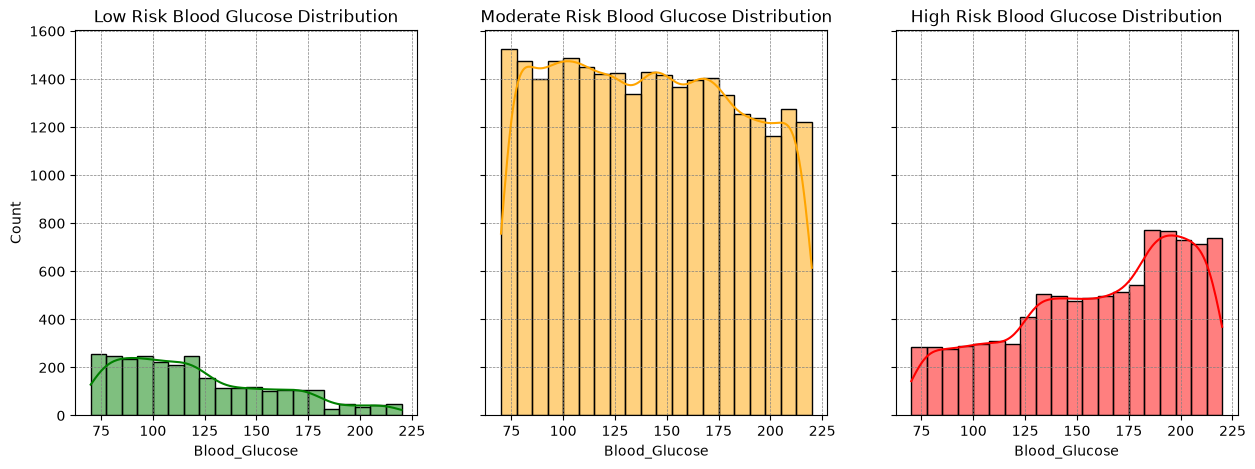

In [23]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['Blood_Glucose'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk Blood Glucose Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['Blood_Glucose'], bins=20, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Moderate Risk Blood Glucose Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['Blood_Glucose'], bins=20, kde=True, ax=axes[2], color='red')
axes[2].set_title('High Risk Blood Glucose Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

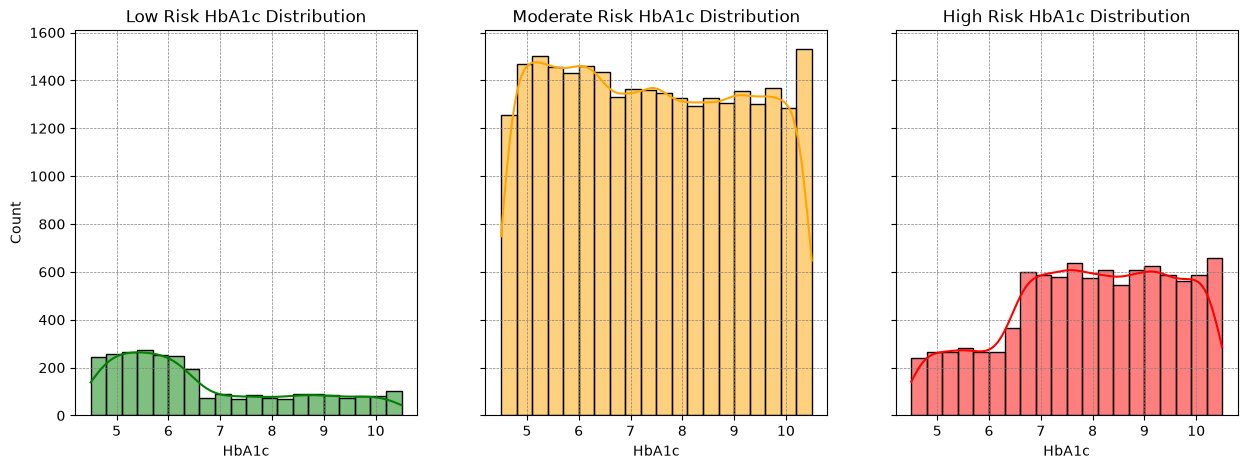

In [24]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['HbA1c'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk HbA1c Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['HbA1c'], bins=20, kde=True, color='orange', ax=axes[1])
axes[1].set_title('Moderate Risk HbA1c Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['HbA1c'], bins=20, kde=True, color='red', ax=axes[2])
axes[2].set_title('High Risk HbA1c Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

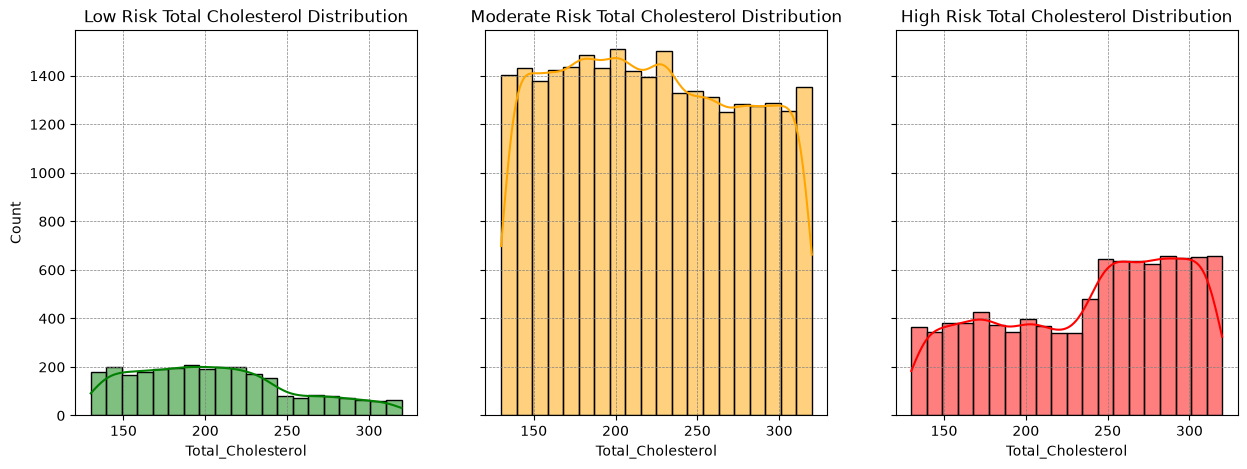

In [25]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['Total_Cholesterol'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk Total Cholesterol Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['Total_Cholesterol'], bins=20, kde=True, color='orange', ax=axes[1])
axes[1].set_title('Moderate Risk Total Cholesterol Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['Total_Cholesterol'], bins=20, kde=True, color='red', ax=axes[2])
axes[2].set_title('High Risk Total Cholesterol Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

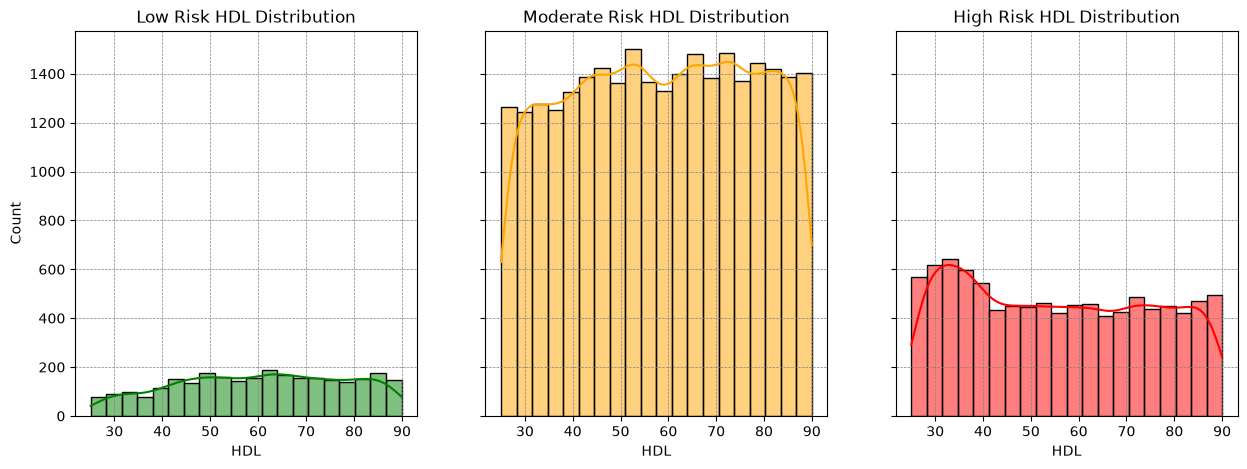

In [26]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['HDL'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk HDL Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['HDL'], bins=20, kde=True, color='orange', ax=axes[1])
axes[1].set_title('Moderate Risk HDL Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['HDL'], bins=20, kde=True, color='red', ax=axes[2])
axes[2].set_title('High Risk HDL Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

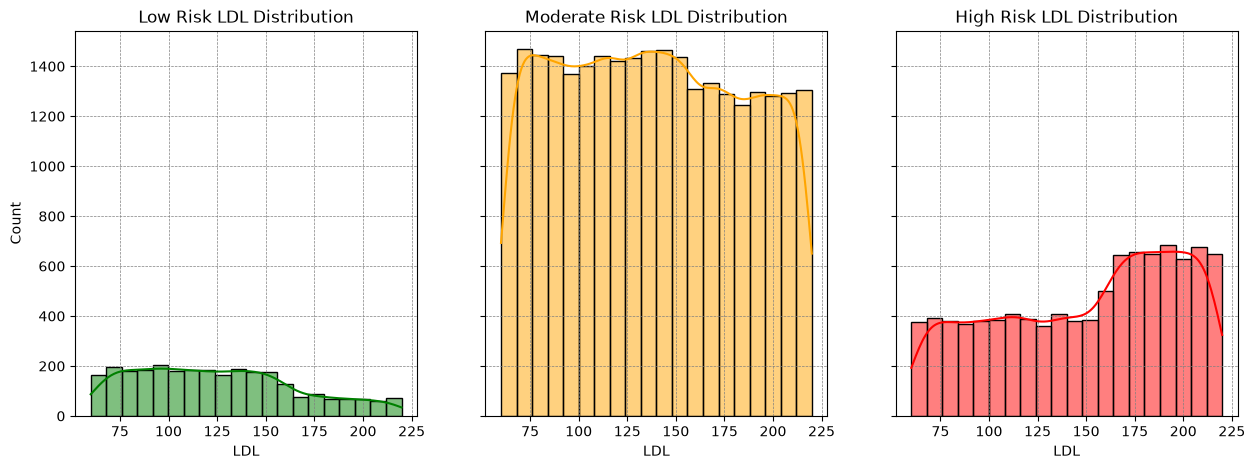

In [27]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['LDL'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk LDL Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['LDL'], bins=20, kde=True, color='orange', ax=axes[1])
axes[1].set_title('Moderate Risk LDL Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['LDL'], bins=20, kde=True, color='red', ax=axes[2])
axes[2].set_title('High Risk LDL Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

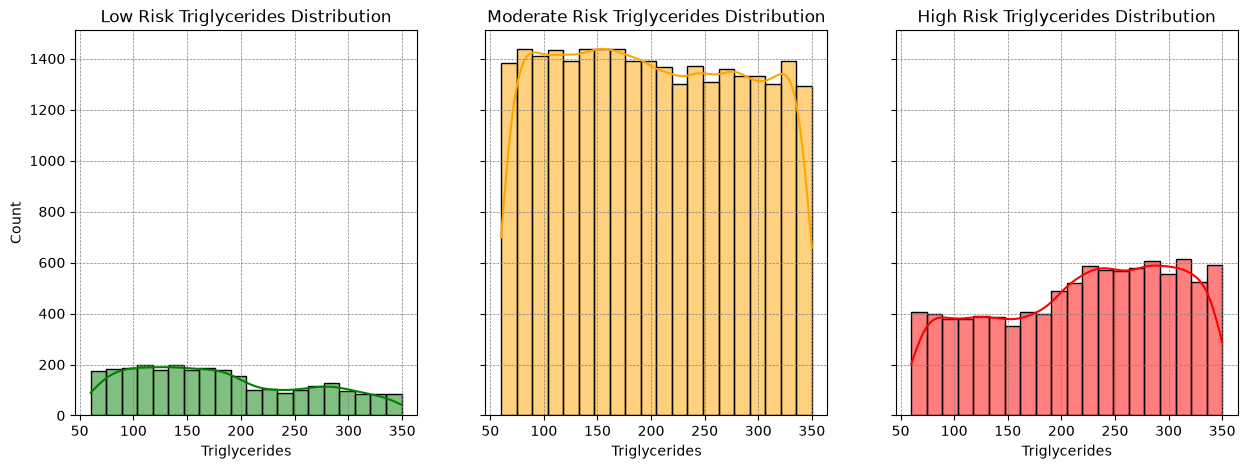

In [28]:
fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

sns.histplot(low_risk['Triglycerides'], bins=20, kde=True, color='green', ax=axes[0])
axes[0].set_title('Low Risk Triglycerides Distribution')
axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(moderate_risk['Triglycerides'], bins=20, kde=True, color='orange', ax=axes[1])
axes[1].set_title('Moderate Risk Triglycerides Distribution')
axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

sns.histplot(high_risk['Triglycerides'], bins=20, kde=True, color='red', ax=axes[2])
axes[2].set_title('High Risk Triglycerides Distribution')
axes[2].grid(color='gray', linestyle='--', linewidth=0.5)

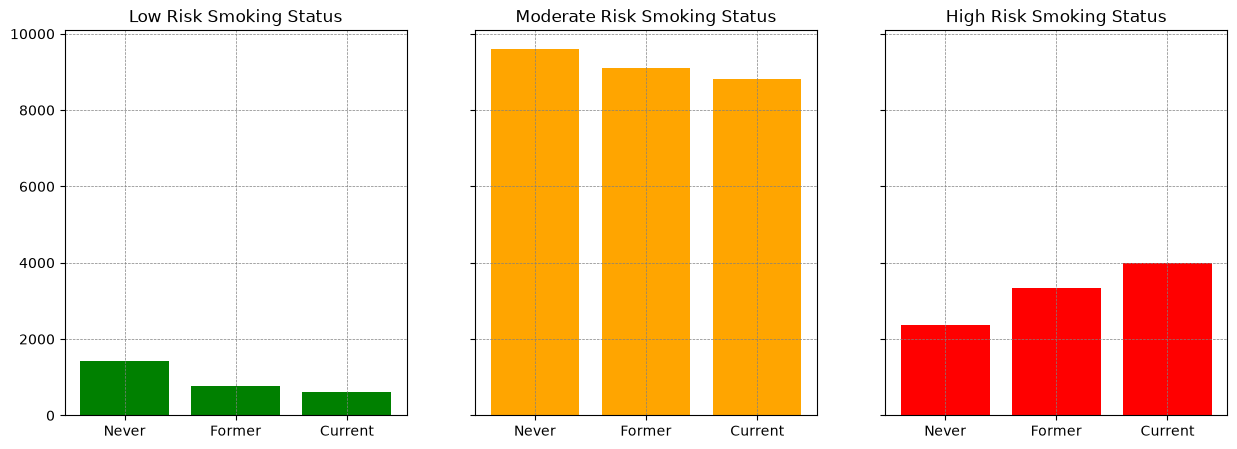

In [29]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

ax.bar(low_risk['Smoking_Status'].value_counts().index, low_risk['Smoking_Status'].value_counts().values, color='green')
ax.set_title('Low Risk Smoking Status')
ax.grid(color='gray', linestyle='--', linewidth=0.5)

bx.bar(moderate_risk['Smoking_Status'].value_counts().index, moderate_risk['Smoking_Status'].value_counts().values, color='orange')
bx.set_title('Moderate Risk Smoking Status')
bx.grid(color='gray', linestyle='--', linewidth=0.5)

cx.bar(high_risk['Smoking_Status'].value_counts(ascending=True).index, high_risk['Smoking_Status'].value_counts(ascending=True).values, color='red')
cx.set_title('High Risk Smoking Status')
cx.grid(color='gray', linestyle='--', linewidth=0.5)

In [30]:
stroke_data['Alcohol_Consumption'].info()

<class 'pandas.Series'>
RangeIndex: 40003 entries, 0 to 40002
Series name: Alcohol_Consumption
Non-Null Count  Dtype
--------------  -----
40003 non-null  str  
dtypes: str(1)
memory usage: 669.5 KB


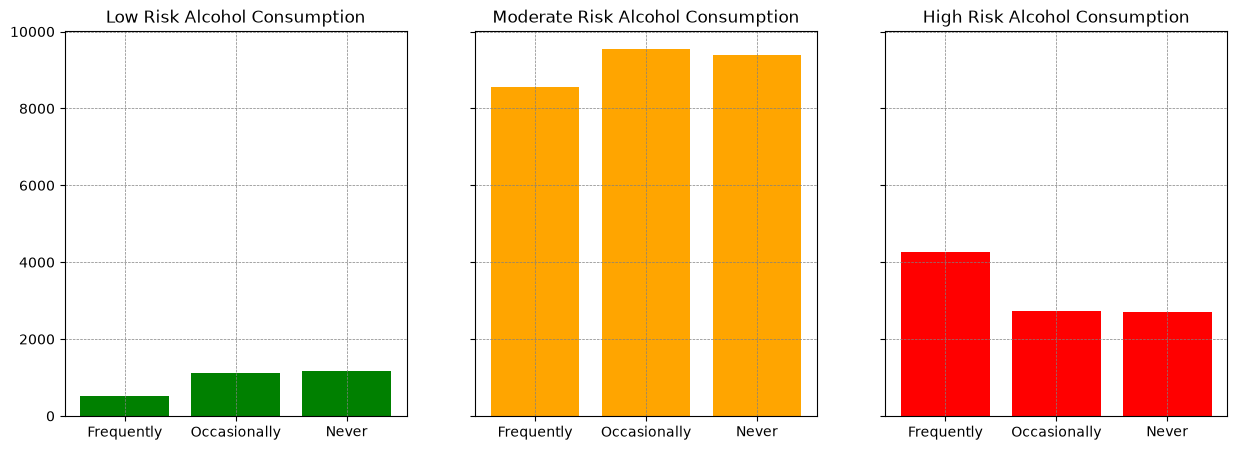

In [31]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

ax.bar(low_risk['Alcohol_Consumption'].value_counts(ascending=True).index, low_risk['Alcohol_Consumption'].value_counts(ascending=True).values, color='green')
ax.set_title('Low Risk Alcohol Consumption')
ax.grid(color='gray', linestyle='--', linewidth=0.5)

order = ['Frequently', 'Occasionally', 'Never']

bx.bar(moderate_risk['Alcohol_Consumption'].value_counts().reindex(order).index, moderate_risk['Alcohol_Consumption'].value_counts().reindex(order).values, color='orange')
bx.set_title('Moderate Risk Alcohol Consumption')
bx.grid(color='gray', linestyle='--', linewidth=0.5)

cx.bar(high_risk['Alcohol_Consumption'].value_counts().index, high_risk['Alcohol_Consumption'].value_counts().values, color='red')
cx.set_title('High Risk Alcohol Consumption')
cx.grid(color='gray', linestyle='--', linewidth=0.5)

In [32]:
# Creating a function to plot the distribution of a given column for each Stroke Risk category
def plot_graph(column_name):
    if low_risk[column_name].dtype == 'float64':
        fig, (axes) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
        sns.histplot(low_risk[column_name], bins=20, kde=True, color='green', ax=axes[0])
        axes[0].set_title(f'Low Risk {column_name} Distribution')
        axes[0].grid(color='gray', linestyle='--', linewidth=0.5)

        sns.histplot(moderate_risk[column_name], bins=20, kde=True, color='orange', ax=axes[1])
        axes[1].set_title(f'Moderate Risk {column_name} Distribution')
        axes[1].grid(color='gray', linestyle='--', linewidth=0.5)

        sns.histplot(high_risk[column_name], bins=20, kde=True, color='red', ax=axes[2])
        axes[2].set_title(f'High Risk {column_name} Distribution')
        axes[2].grid(color='gray', linestyle='--', linewidth=0.5)
    elif low_risk[column_name].dtype == 'str':
        fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

        values = low_risk[column_name].unique().tolist()

        if set(values).issubset({'Frequently', 'Occasionally', 'Never'}):
            order = ['Frequently', 'Occasionally', 'Never']

        elif set(values).issubset({'Low', 'Moderate', 'High'}):
            order = ['Low', 'Moderate', 'High']

        else:
            order = low_risk[column_name].value_counts().index.tolist()
        
        ax.bar(low_risk[column_name].value_counts().reindex(order).index, low_risk[column_name].value_counts().reindex(order).values, color='green')
        ax.set_title(f'Low Risk {column_name} Distribution')
        ax.grid(color='gray', linestyle='--', linewidth=0.5)

        bx.bar(moderate_risk[column_name].value_counts().reindex(order).index, moderate_risk[column_name].value_counts().reindex(order).values, color='orange')
        bx.set_title(f'Moderate Risk {column_name} Distribution')
        bx.grid(color='gray', linestyle='--', linewidth=0.5)

        cx.bar(high_risk[column_name].value_counts().reindex(order).index, high_risk[column_name].value_counts().reindex(order).values, color='red')
        cx.set_title(f'High Risk {column_name} Distribution')
        cx.grid(color='gray', linestyle='--', linewidth=0.5)
    else:
        print(f"Column '{column_name}' is not a valid column for plotting. Column type is {low_risk[column_name].dtype}.")

Column 'Patient_ID' is not a valid column for plotting. Column type is int64.
Column 'Blood_Pressure_Systolic' is not a valid column for plotting. Column type is int64.
Column 'Blood_Pressure_Diastolic' is not a valid column for plotting. Column type is int64.
Column 'Heart_Rate' is not a valid column for plotting. Column type is int64.


C:\Users\madki\AppData\Local\Temp\ipykernel_12836\3369188538.py:17: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(15, 5), sharey=True)


Column 'Stroke_Risk_Score' is not a valid column for plotting. Column type is int64.


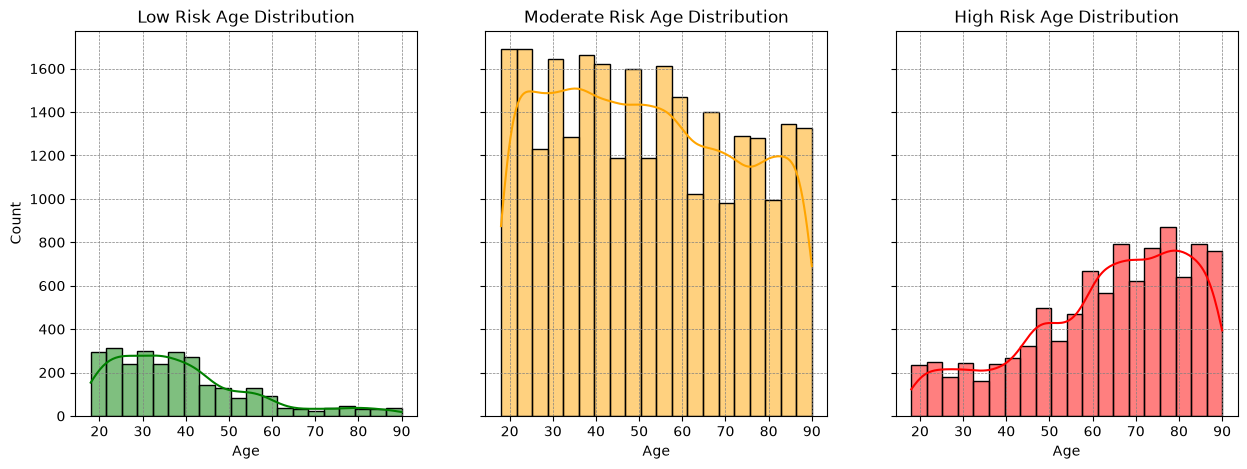

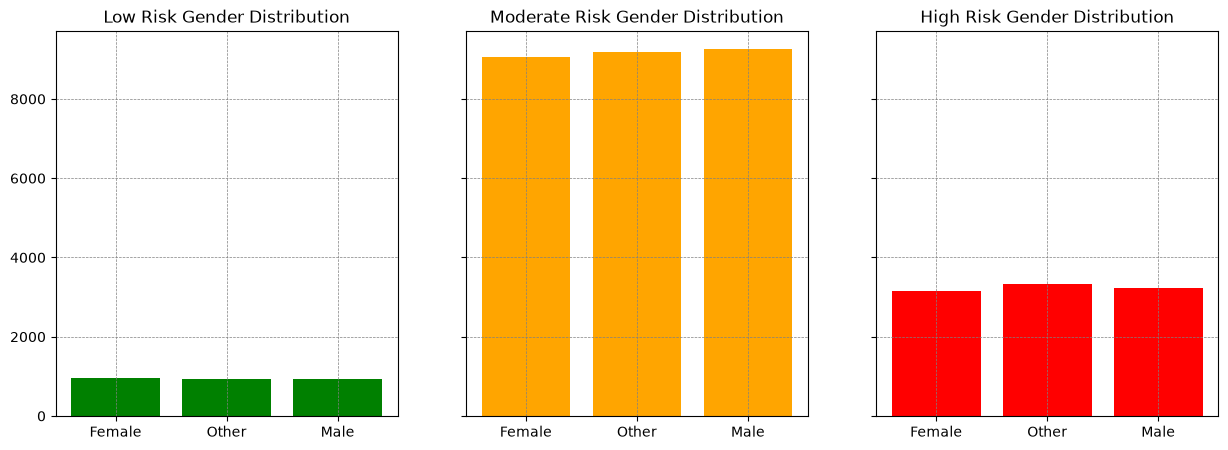

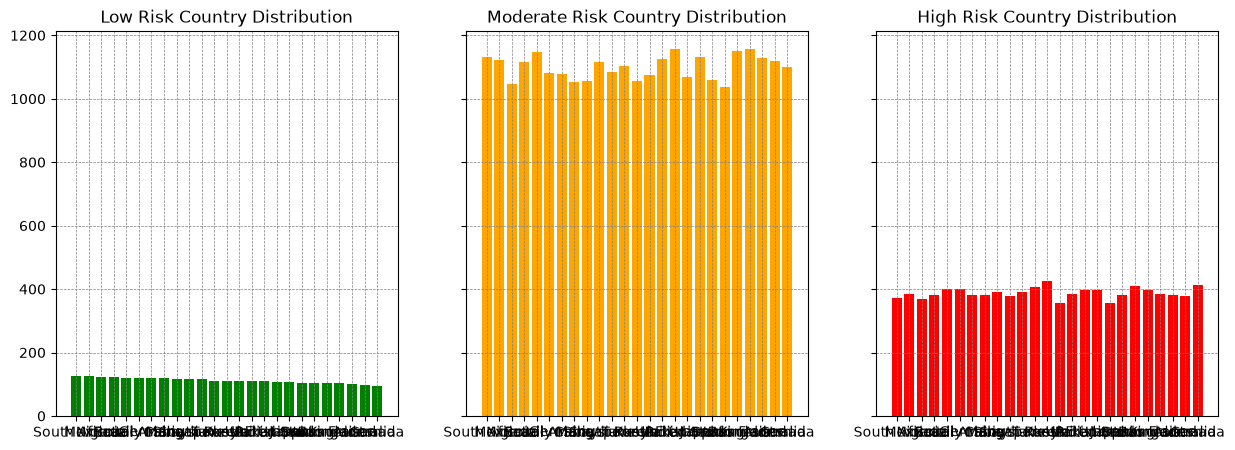

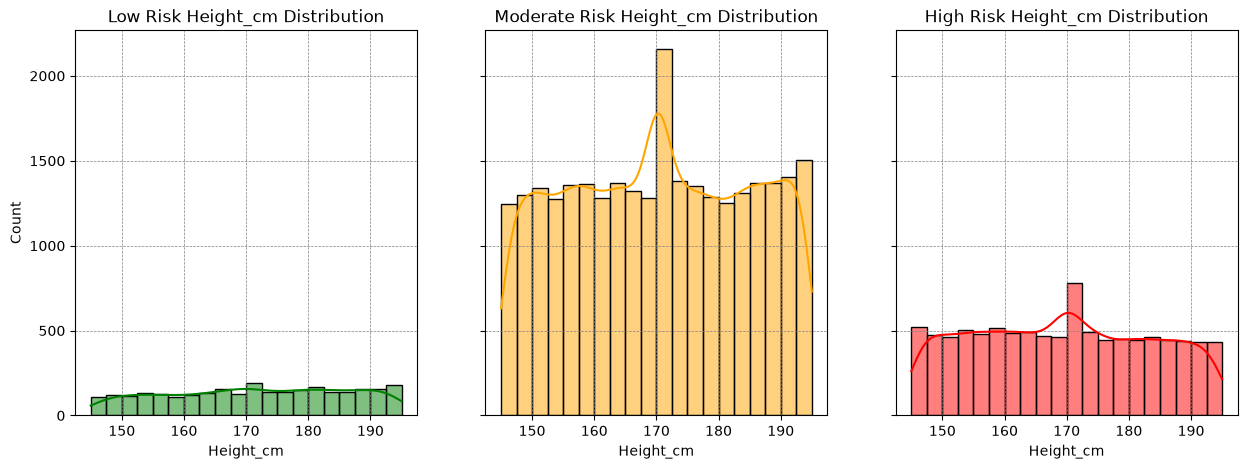

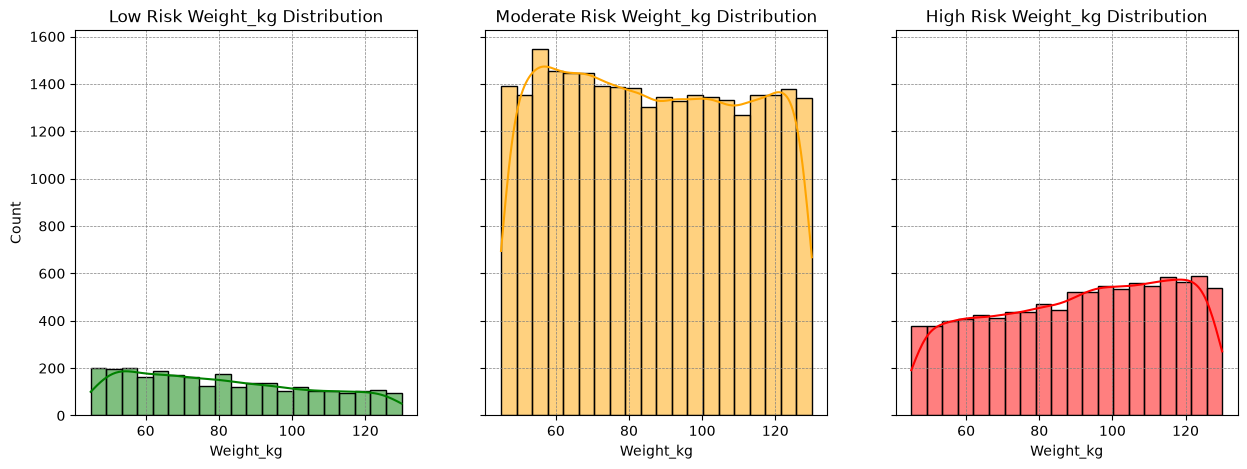

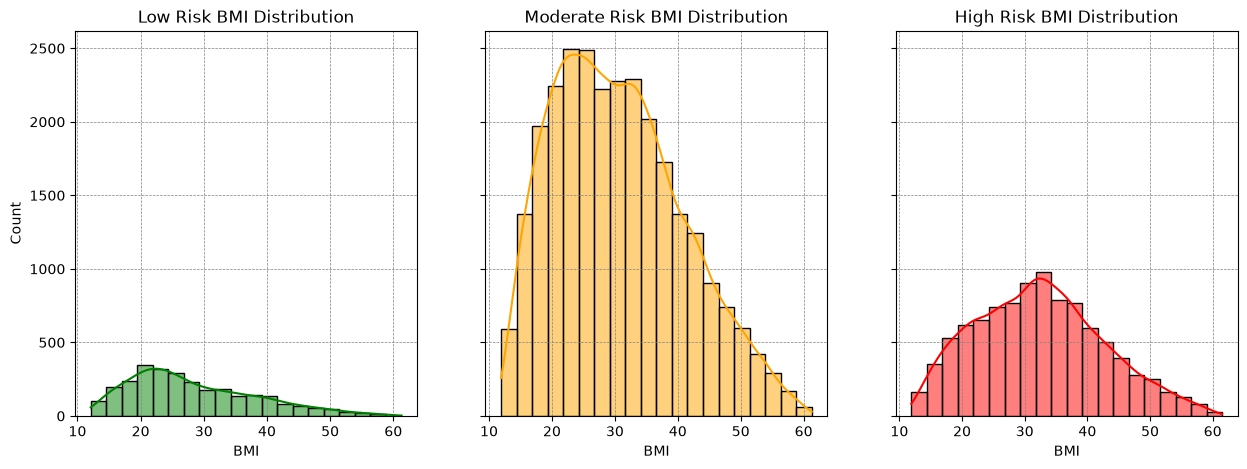

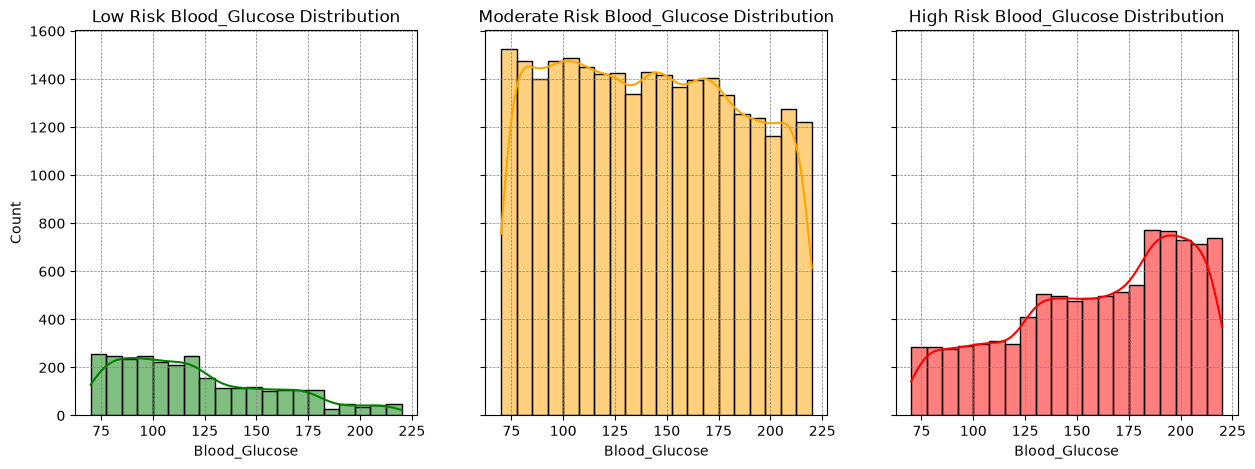

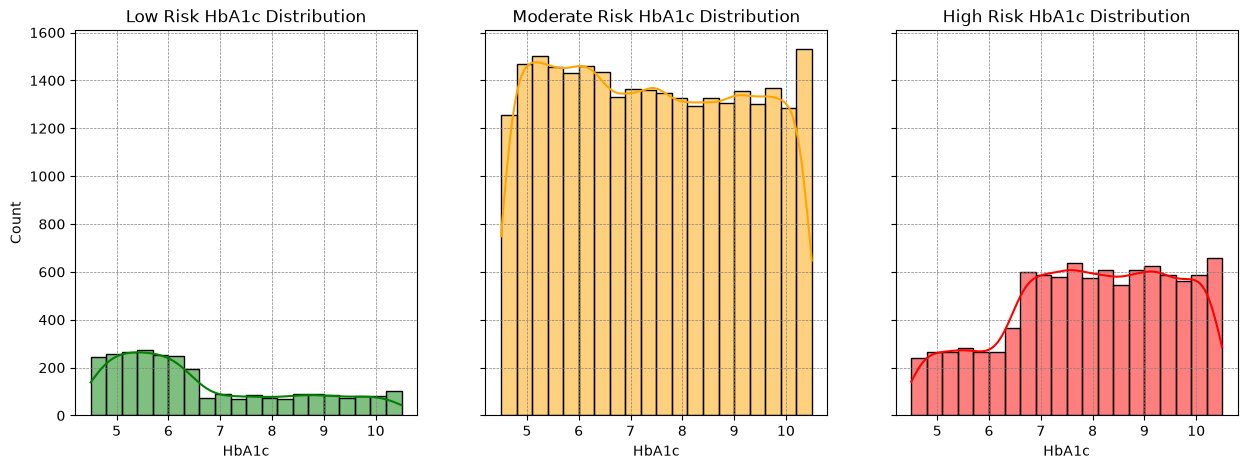

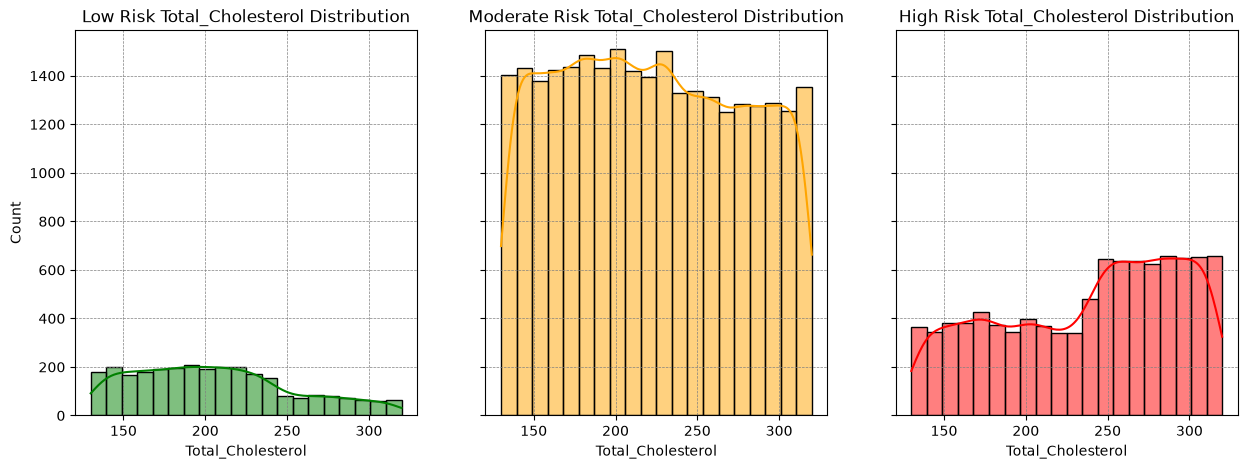

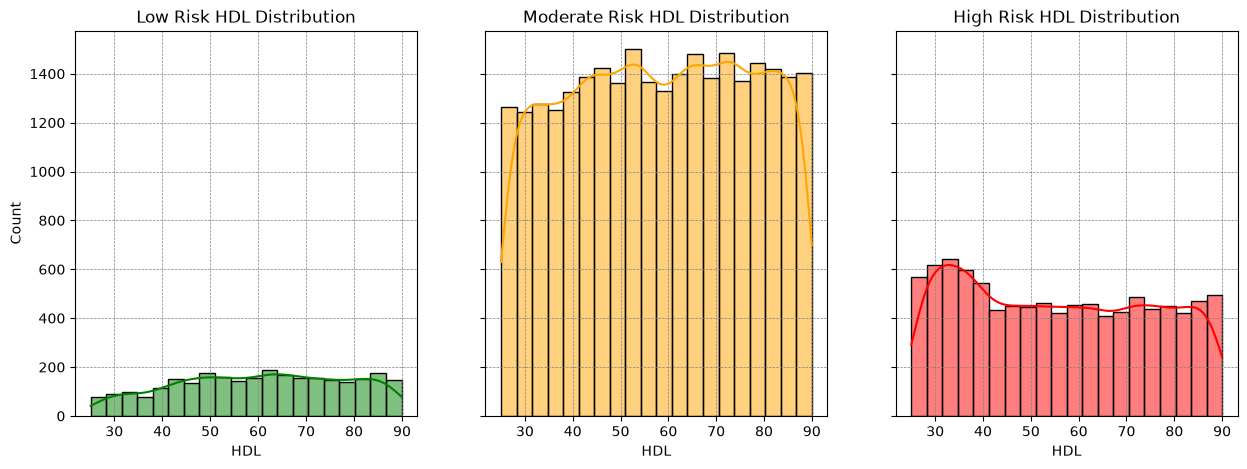

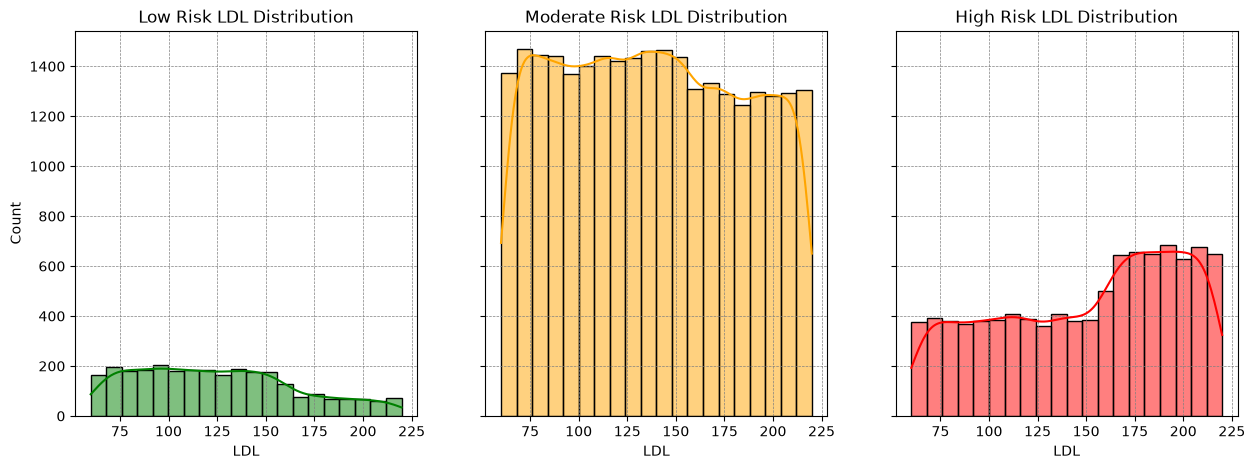

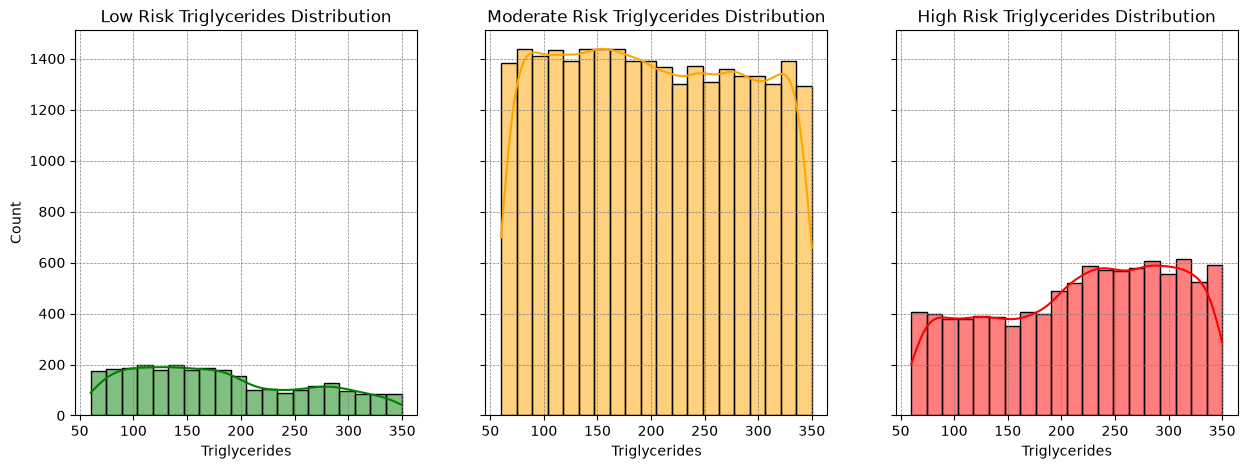

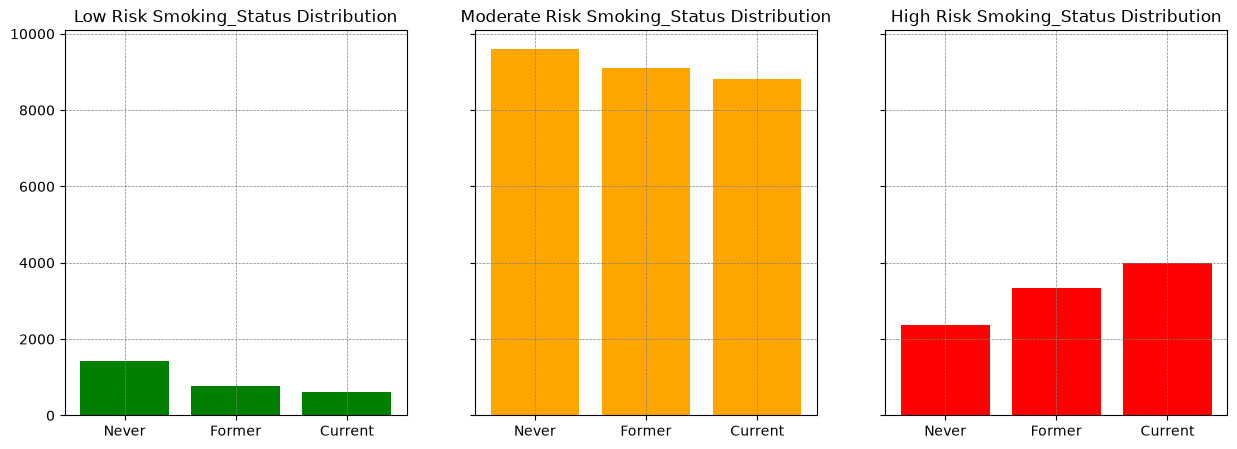

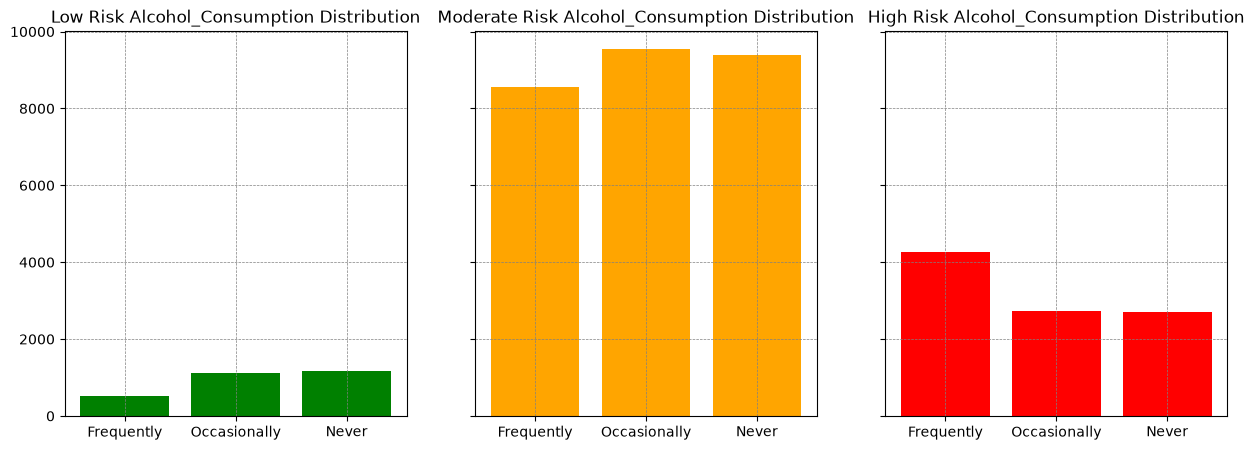

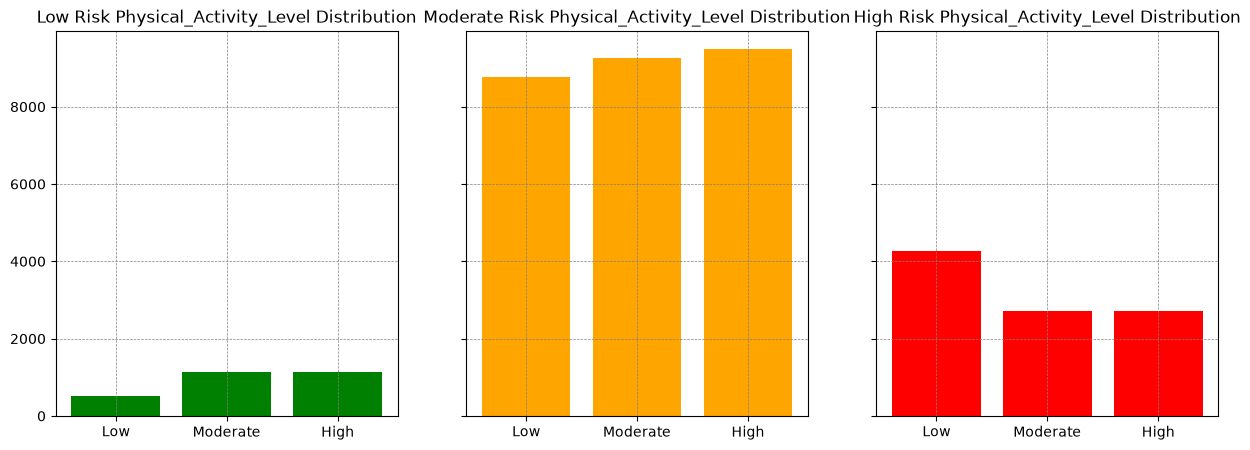

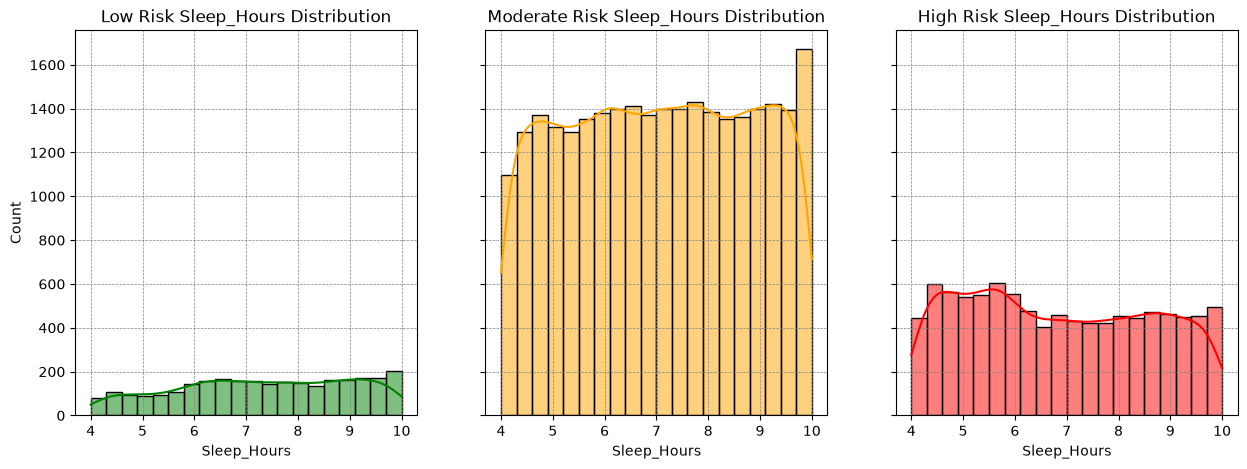

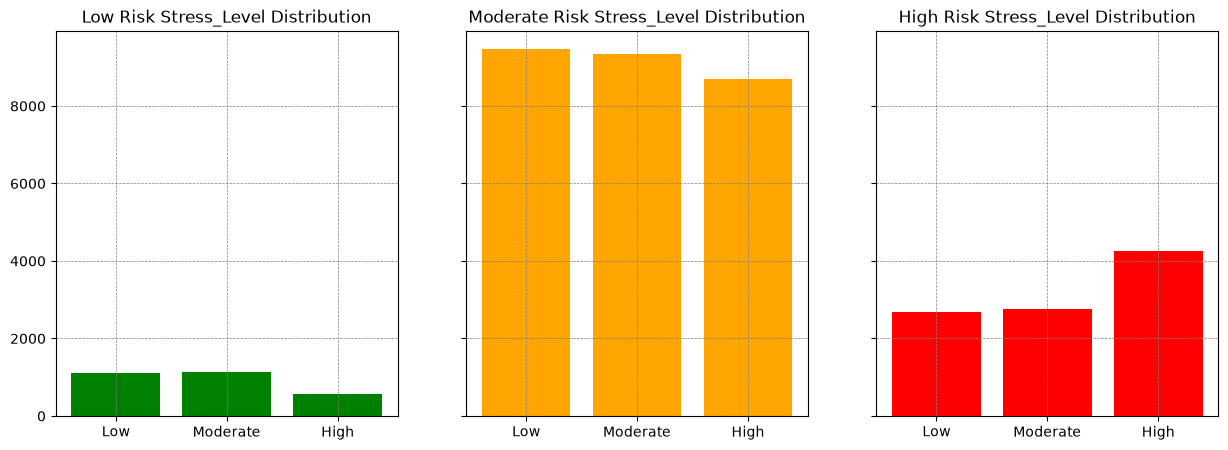

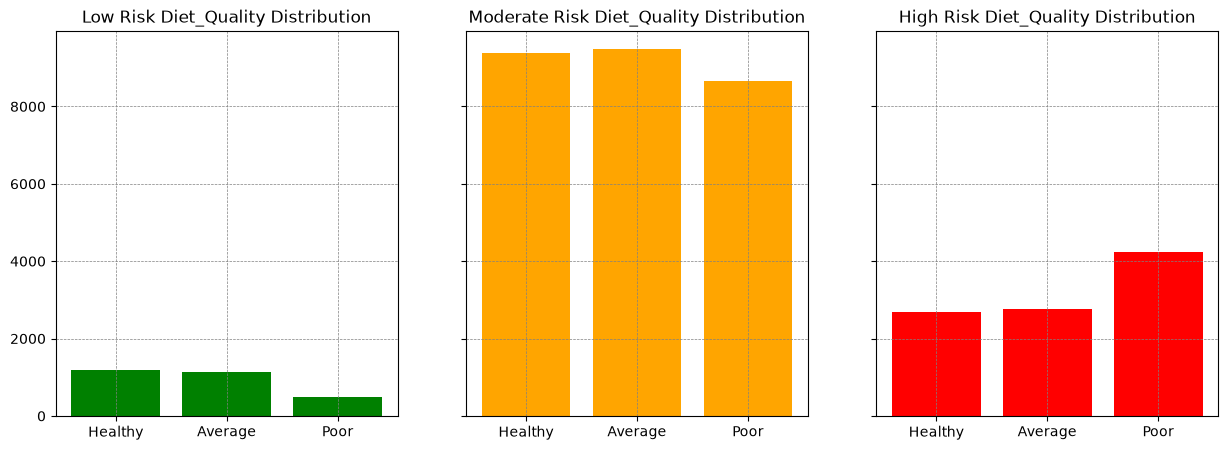

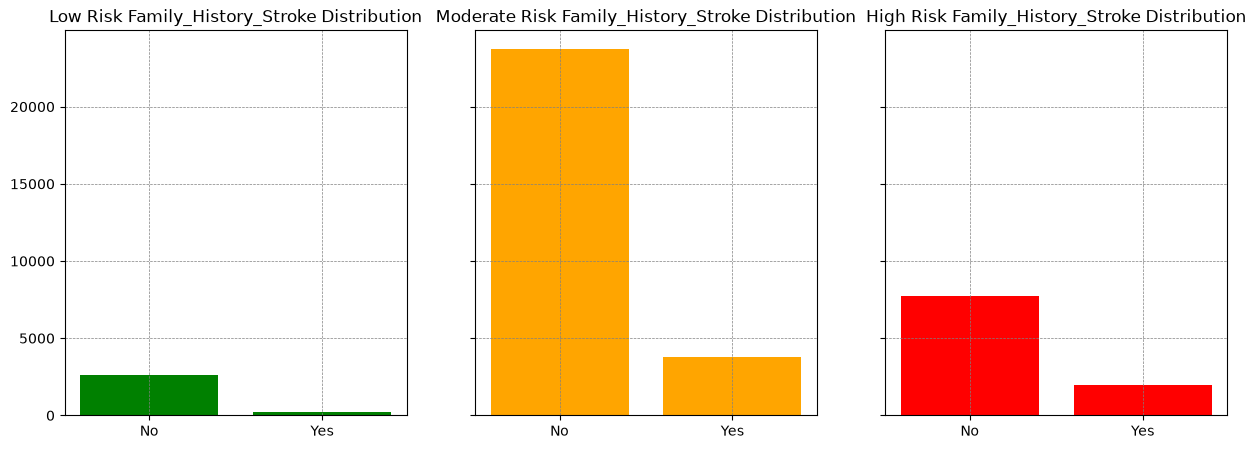

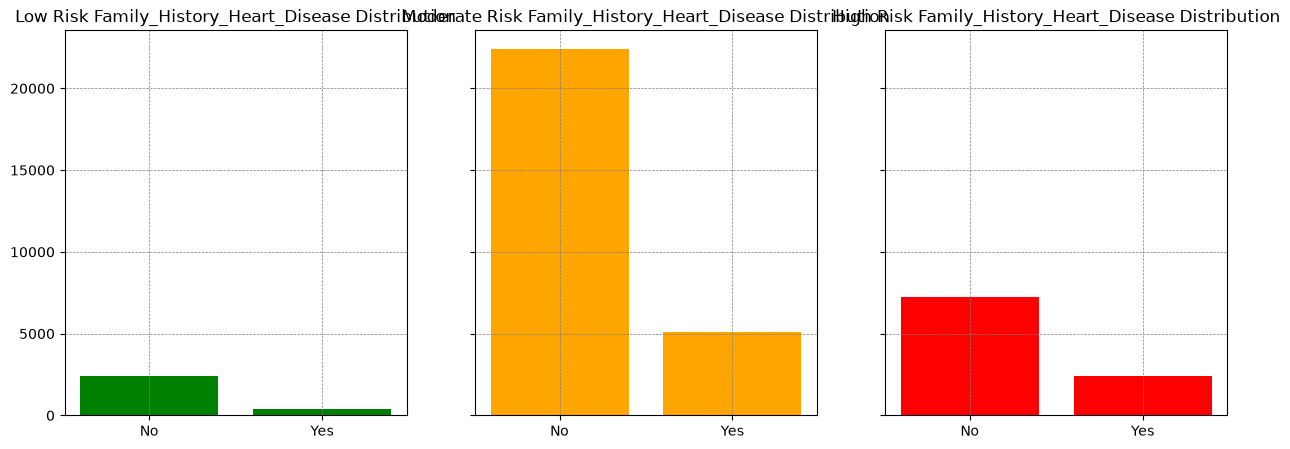

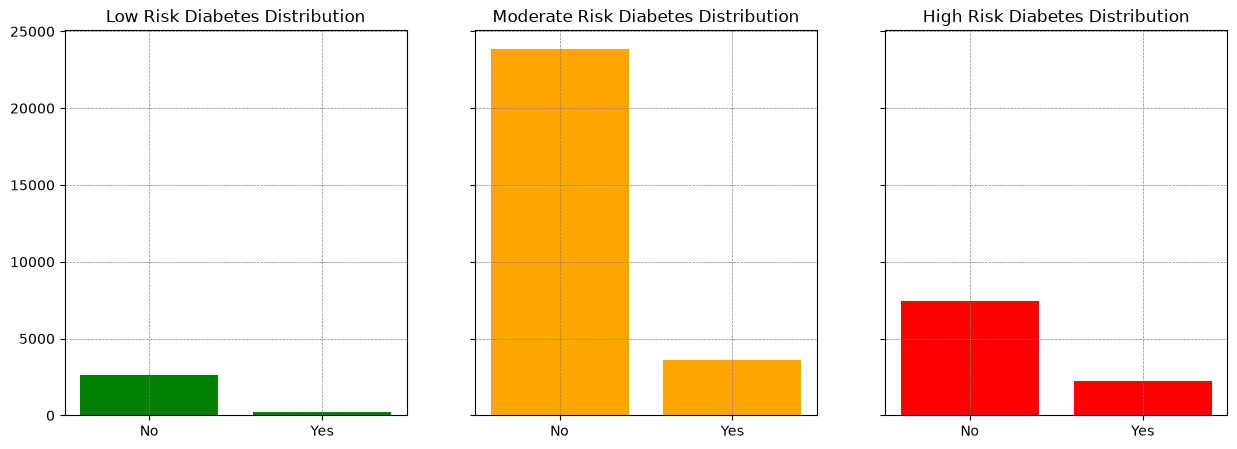

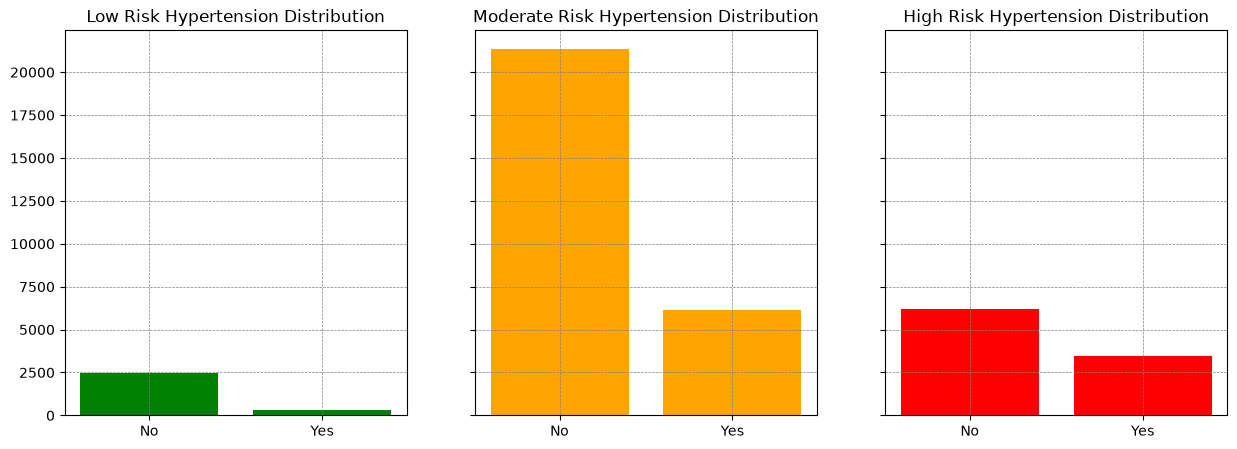

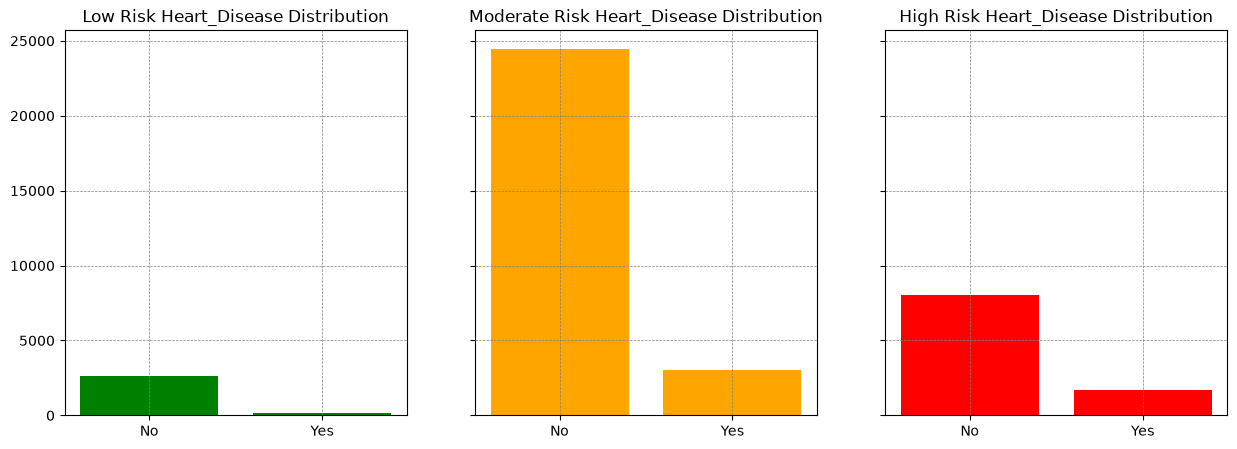

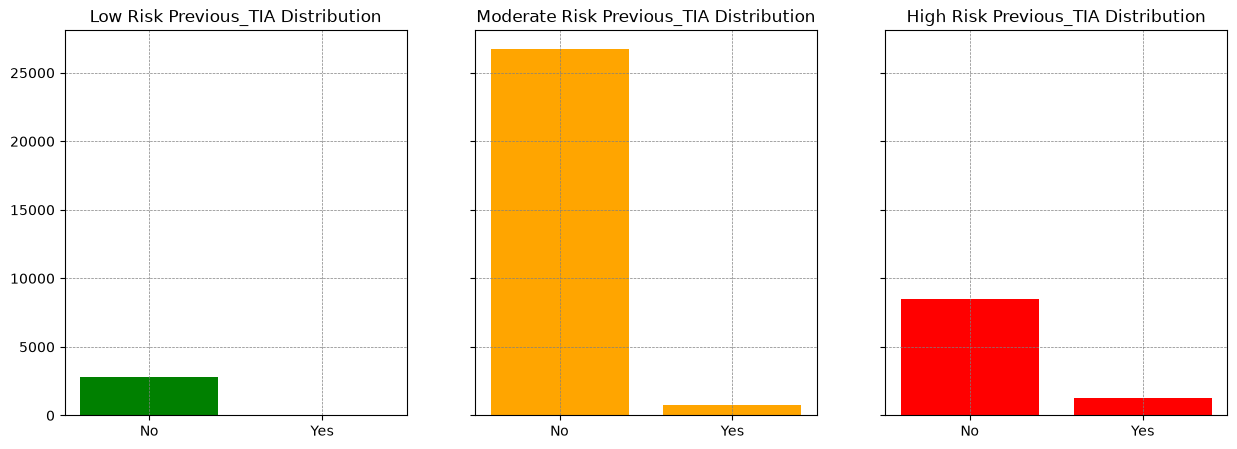

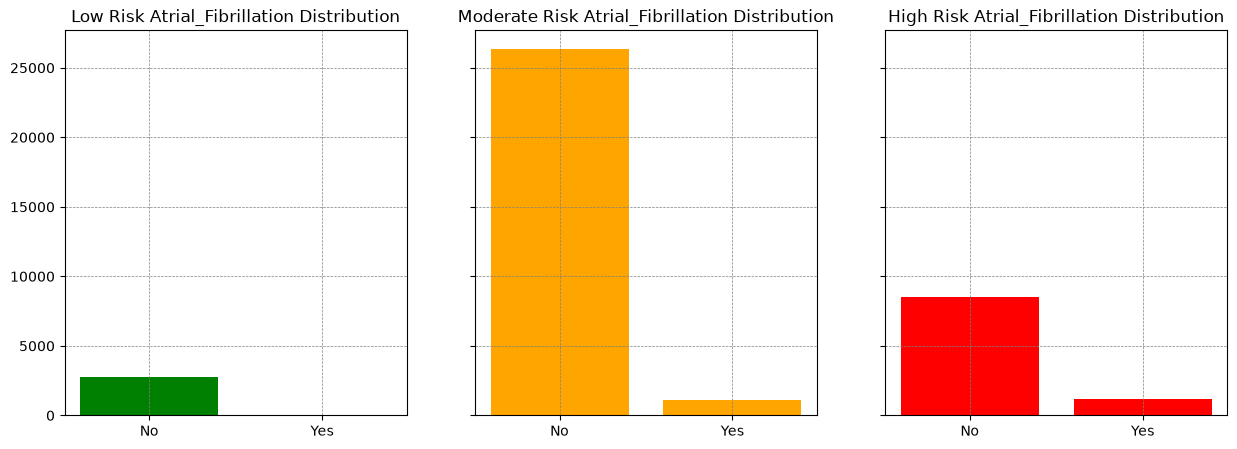

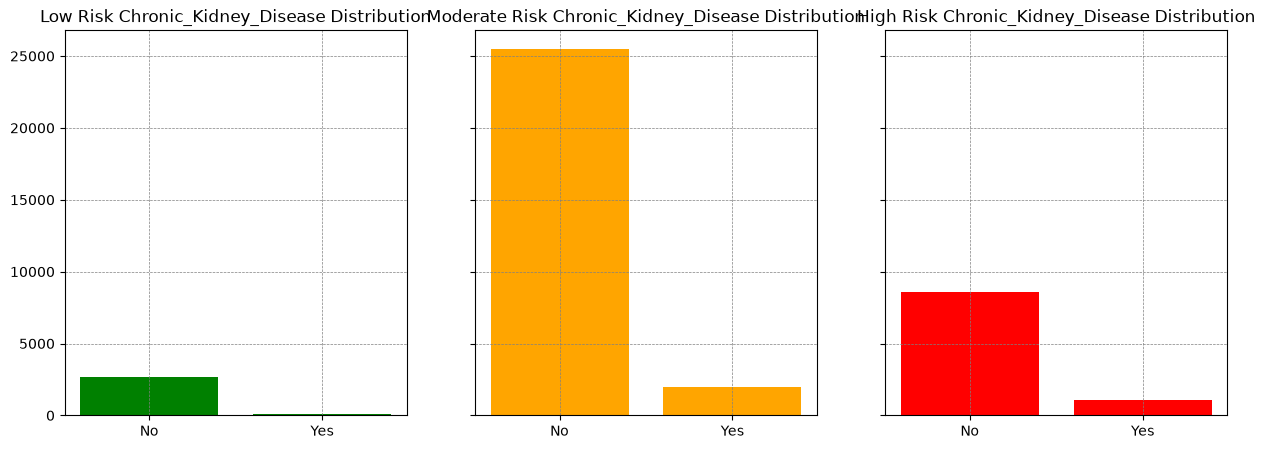

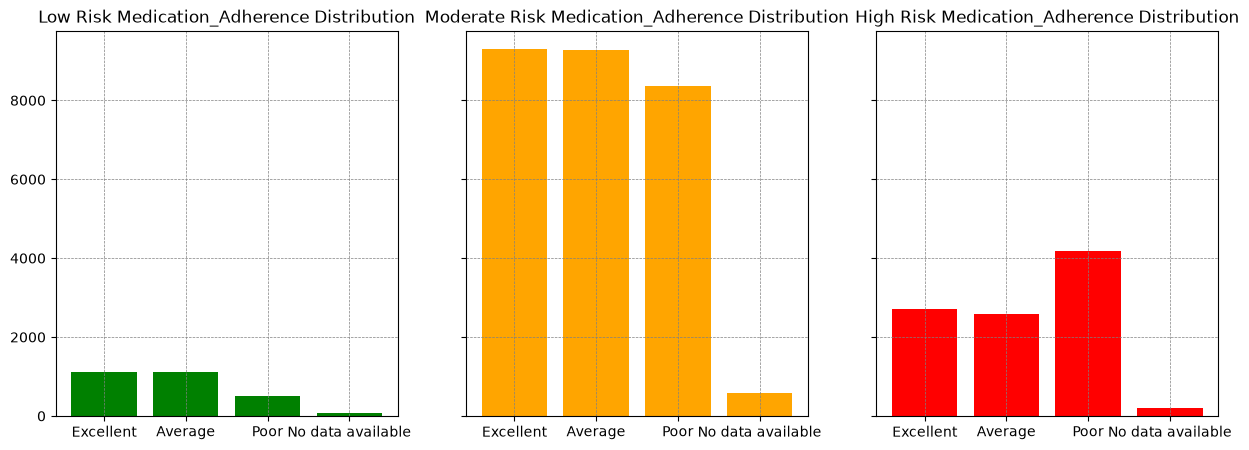

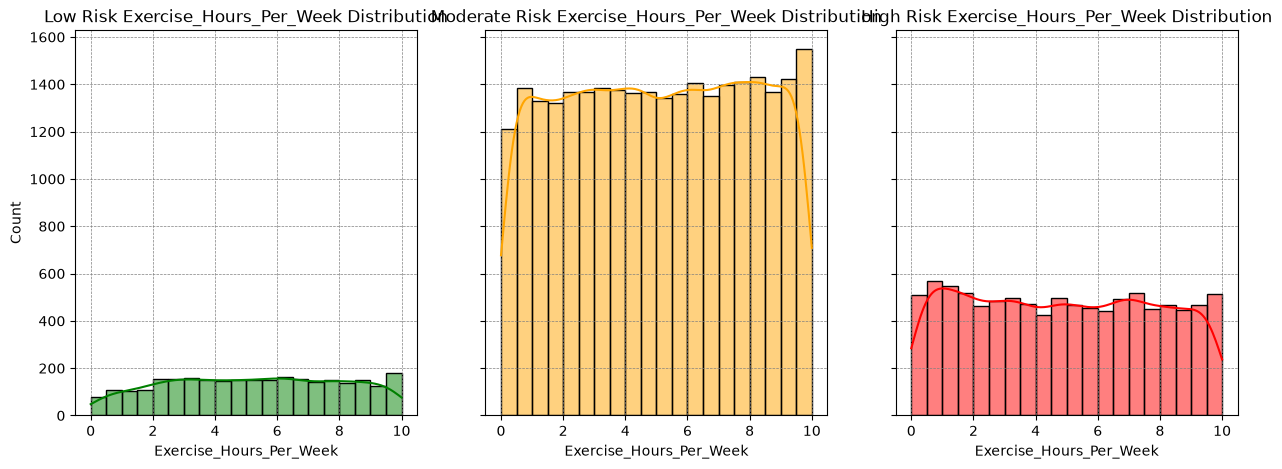

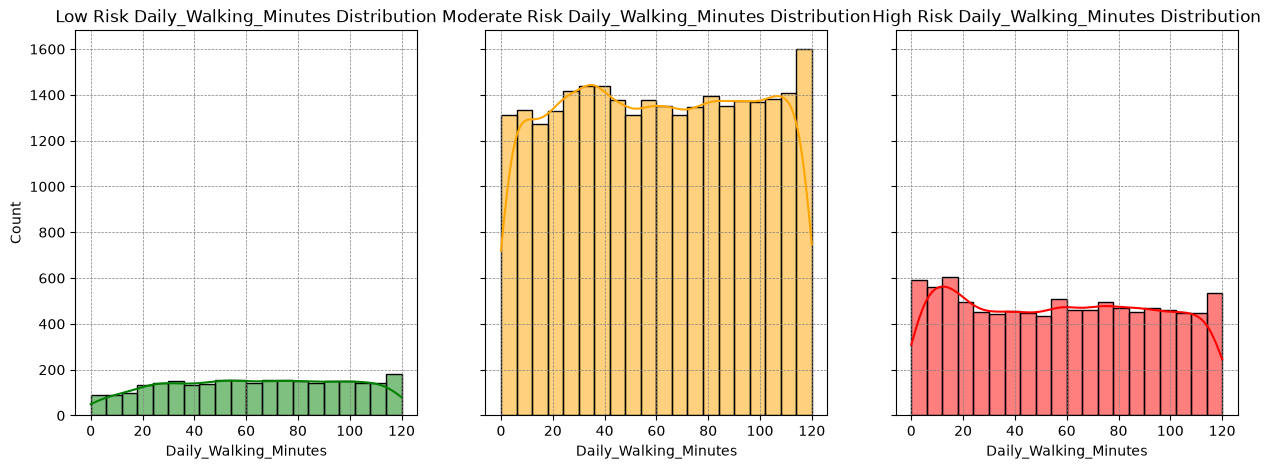

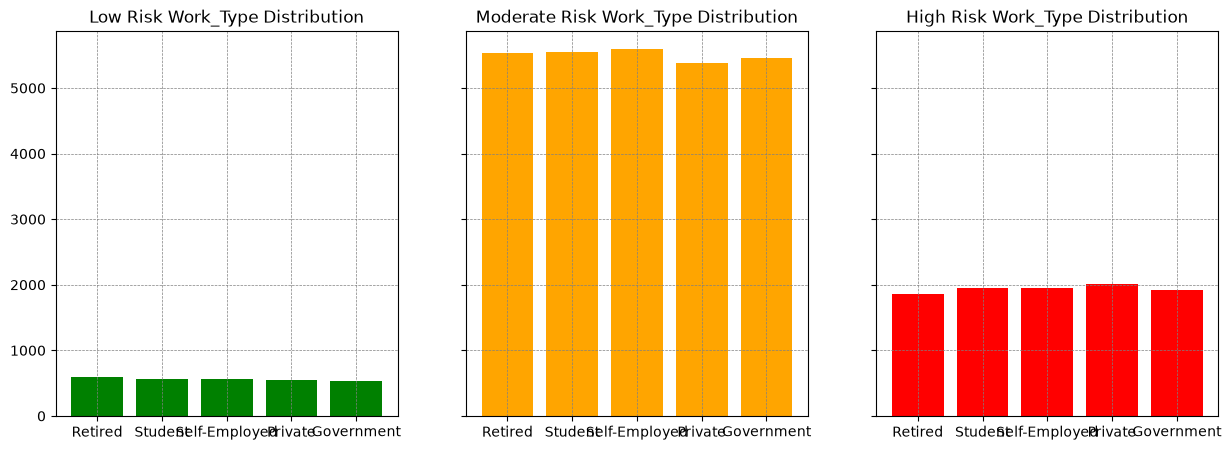

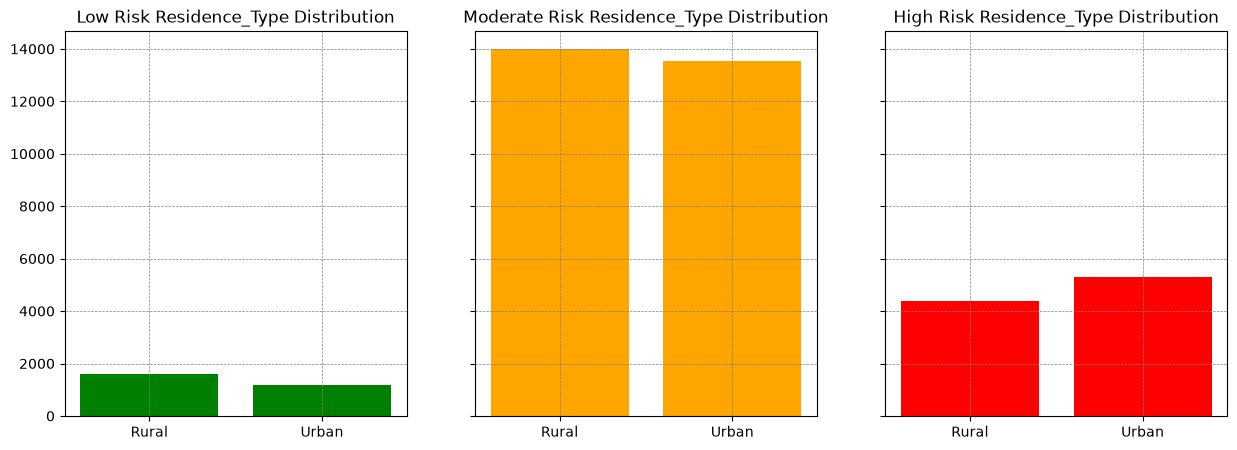

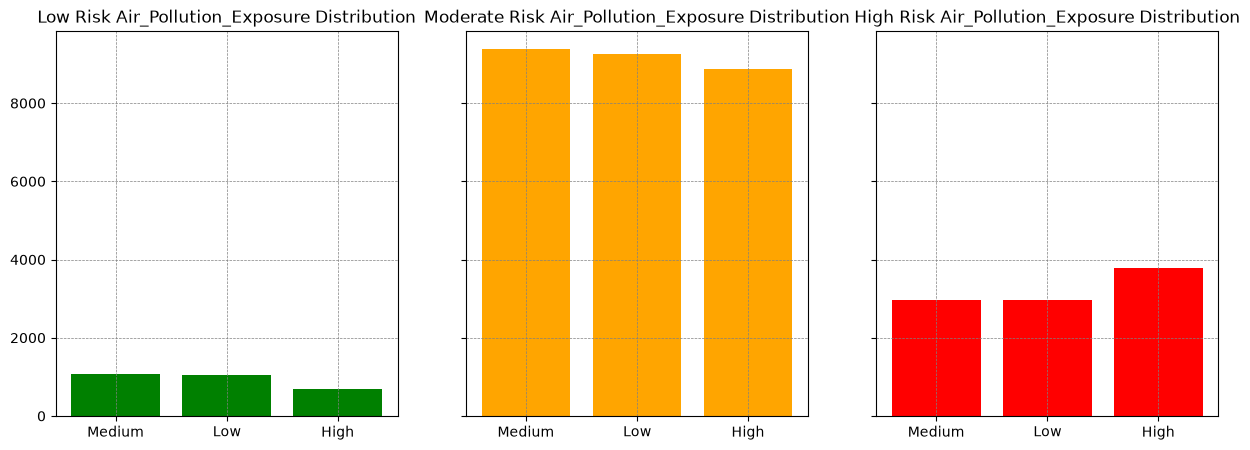

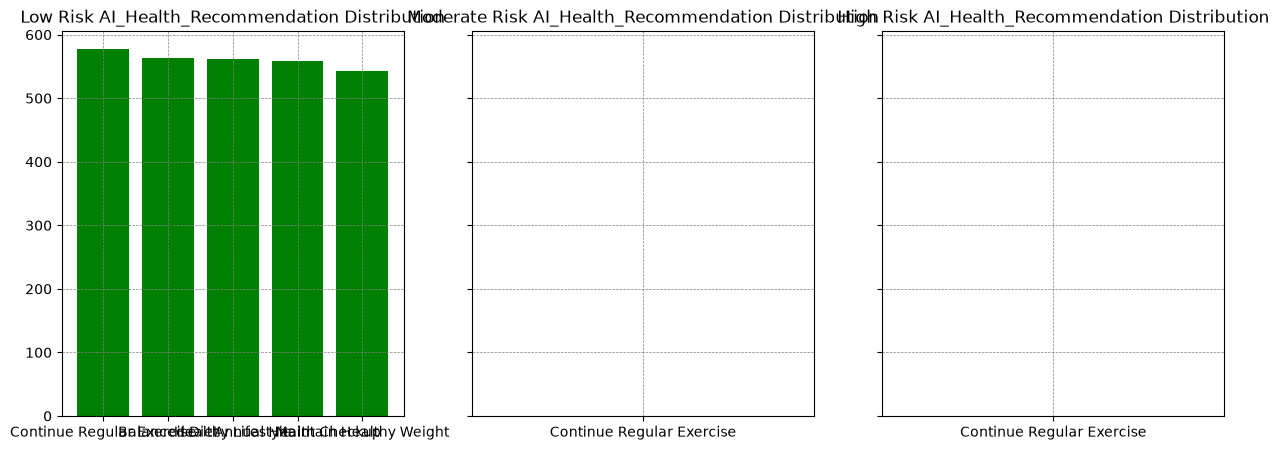

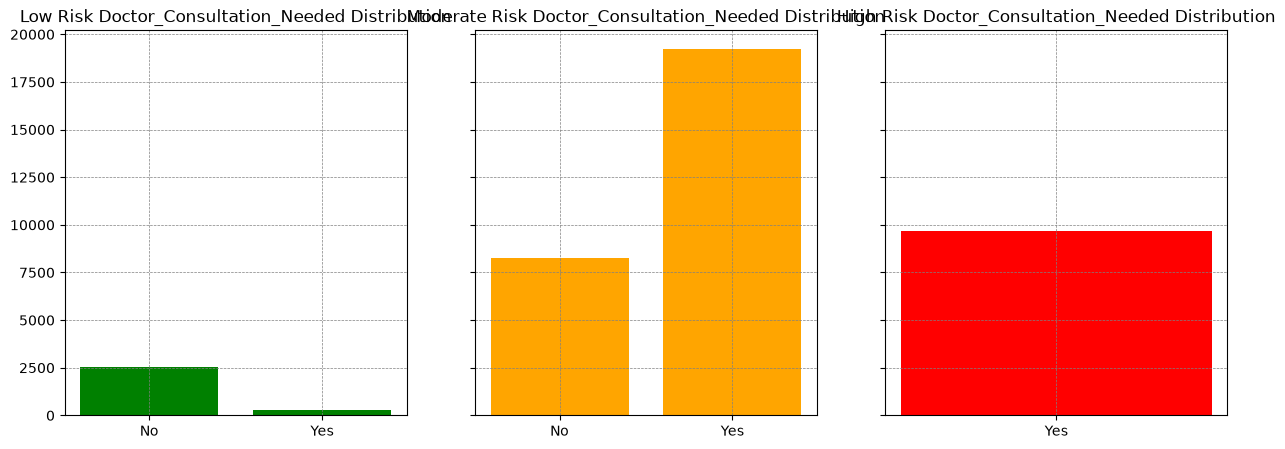

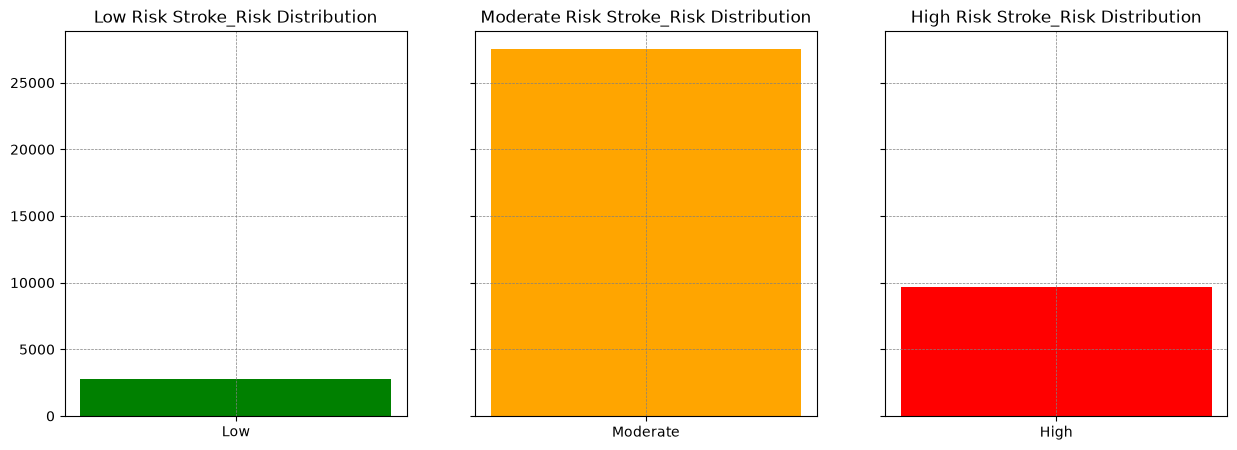

In [33]:
#Using a loop to plot graphs for all columns in the dataset

for column in stroke_data.columns:
    plot_graph(column)


In [34]:
stroke_data_numerics = stroke_data.select_dtypes(include=['float64', 'int64'])

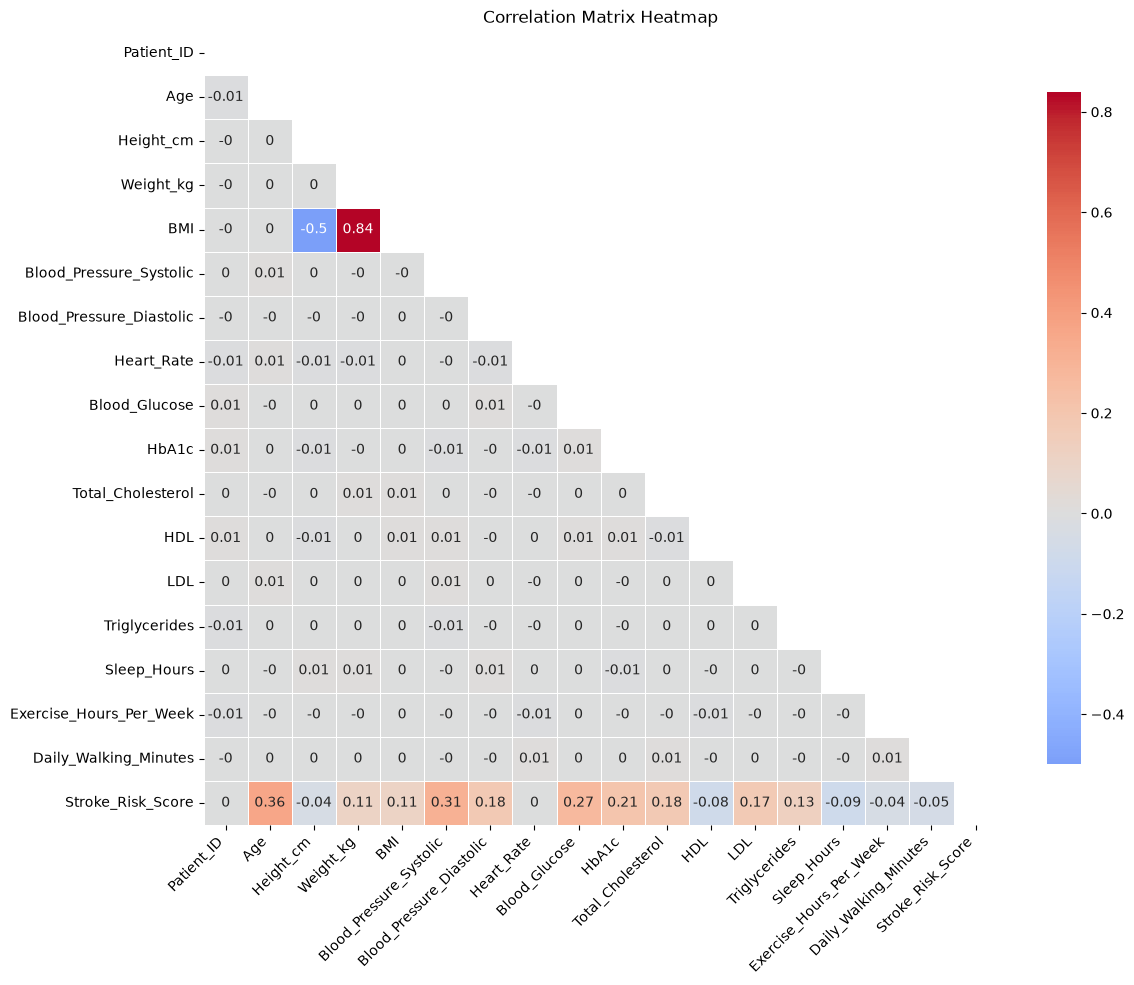

In [35]:
# Creating a correlation matrix heatmap for the numeric columns in the dataset
cm = stroke_data_numerics.corr().round(2)
mask = np.triu(np.ones_like(cm, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(cm, annot=True, cmap='coolwarm', center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax, mask=mask)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout(pad=0.5)

plt.show()

In [36]:
stroke_data = stroke_data.drop(columns=['Patient_ID', 'Stroke_Risk_Score'])

In [37]:
#Coding a function that calculates the chi square of a DataFrame categorical variable

def chi_square_test(df: pd.DataFrame, col1: str, col2: str):
    """
    Função para realizar o teste qui-quadrado de independência entre duas variáveis categóricas.
    
    Parâmetros:
    df: dataframe a ser analisado
    col1: nome da primeira coluna categórica
    col2: nome da segunda coluna categórica
    
    Retorna:
    O valor do qui-quadrado, p-value e a tabela de contingência.
    """
    tabela = pd.crosstab(df[col1], df[col2])
    
    chi2, p, g1, esperado = chi2_contingency(tabela)

    print("Chi test for independence between '{}' and '{}'".format(col1, col2))
    print("Chi-squared:", chi2.round(2))
    print("p-value:", p)

    if p < 0.05:
        print("A association exist.")
        cramers_v = np.sqrt(chi2 / (df.shape[0] * (min(tabela.shape) - 1)))
        if cramers_v < 0.1:
            print("The association is too weak.")
        elif cramers_v < 0.3:
            print("The association is weak.")
        else:
            print("There is a strong association.")
    else:
        print("There is no evidence for an association.")
        
    print("Contingency Table:")
    print(tabela)
    print("\n")
    return chi2, p, tabela

In [38]:
stroke_data_categoricals = stroke_data.select_dtypes(include='str')
stroke_data_categoricals.info()

<class 'pandas.DataFrame'>
RangeIndex: 40003 entries, 0 to 40002
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Gender                        40003 non-null  str  
 1   Country                       40003 non-null  str  
 2   Smoking_Status                40003 non-null  str  
 3   Alcohol_Consumption           40003 non-null  str  
 4   Physical_Activity_Level       40003 non-null  str  
 5   Stress_Level                  40003 non-null  str  
 6   Diet_Quality                  40003 non-null  str  
 7   Family_History_Stroke         40003 non-null  str  
 8   Family_History_Heart_Disease  40003 non-null  str  
 9   Diabetes                      40003 non-null  str  
 10  Hypertension                  40003 non-null  str  
 11  Heart_Disease                 40003 non-null  str  
 12  Previous_TIA                  40003 non-null  str  
 13  Atrial_Fibrillation           40003 non-nu

In [39]:
# Running the chi square test for each categorical column against 'Stroke_Risk'
for col1 in stroke_data_categoricals.columns:
    chi_square_test(stroke_data_categoricals, col1, 'Stroke_Risk')

Chi test for independence between 'Gender' and 'Stroke_Risk'
Chi-squared: 4.26
p-value: 0.3719842933286603
There is no evidence for an association.
Contingency Table:
Stroke_Risk  High  Low  Moderate
Gender                          
Female       3145  951      9068
Male         3222  920      9254
Other        3327  933      9183


Chi test for independence between 'Country' and 'Stroke_Risk'
Chi-squared: 42.12
p-value: 0.7115034544527274
There is no evidence for an association.
Contingency Table:
Stroke_Risk     High  Low  Moderate
Country                            
Australia        379   99      1119
Bangladesh       386  103      1156
Brazil           382  124      1116
Canada           412   94      1101
China            381  119      1054
France           380  101      1130
Germany          380  119      1077
India            383  110      1126
Indonesia        398  105      1152
Italy            400  120      1148
Japan            357  106      1133
Malaysia         391  118    

In [40]:
low_risk_profile = low_risk.select_dtypes(include=['int64', 'float64']).mean()

In [41]:
low_risk_profile

Patient_ID                  25291.236091
Age                            39.060984
Height_cm                     171.509843
Weight_kg                      81.436448
BMI                            28.297432
Blood_Pressure_Systolic       123.575963
Blood_Pressure_Diastolic       79.645506
Heart_Rate                     82.525678
Blood_Glucose                 121.650999
HbA1c                           6.638659
Total_Cholesterol             205.472967
HDL                            60.384201
LDL                           124.780920
Triglycerides                 181.984593
Sleep_Hours                     7.291262
Exercise_Hours_Per_Week         5.245613
Daily_Walking_Minutes          63.467903
Stroke_Risk_Score              28.833452
dtype: float64

In [42]:
for column in low_risk.select_dtypes(include=['str']).columns:
    low_risk_profile[column] = low_risk[column].mode()[0]

In [43]:
# The average values for the numeric columns and the most frequent values for the categorical columns in the low risk profile
low_risk_profile

Patient_ID                                   25291.236091
Age                                             39.060984
Height_cm                                      171.509843
Weight_kg                                       81.436448
BMI                                             28.297432
Blood_Pressure_Systolic                        123.575963
Blood_Pressure_Diastolic                        79.645506
Heart_Rate                                      82.525678
Blood_Glucose                                  121.650999
HbA1c                                            6.638659
Total_Cholesterol                              205.472967
HDL                                             60.384201
LDL                                             124.78092
Triglycerides                                  181.984593
Sleep_Hours                                      7.291262
Exercise_Hours_Per_Week                          5.245613
Daily_Walking_Minutes                           63.467903
Stroke_Risk_Sc

In [44]:
moderate_risk_profile = moderate_risk.select_dtypes(include=['int64', 'float64']).mean()

In [45]:
for column in moderate_risk.select_dtypes(include=['str']).columns:
    moderate_risk_profile[column] = moderate_risk[column].mode()[0]

In [46]:
# The average values for the numeric columns and the most frequent values for the categorical columns in the moderate risk profile
moderate_risk_profile

Patient_ID                                24919.772151
Age                                          52.006508
Height_cm                                   170.289202
Weight_kg                                    86.820629
BMI                                          30.601029
Blood_Pressure_Systolic                     133.331976
Blood_Pressure_Diastolic                      84.17615
Heart_Rate                                   82.519506
Blood_Glucose                               142.273281
HbA1c                                         7.425061
Total_Cholesterol                            222.68016
HDL                                          58.128464
LDL                                         138.179513
Triglycerides                               202.781062
Sleep_Hours                                   7.036982
Exercise_Hours_Per_Week                       5.040862
Daily_Walking_Minutes                        60.300164
Stroke_Risk_Score                            50.970951
Gender    

In [47]:
high_risk_profile = high_risk.select_dtypes(include=['int64', 'float64']).mean()

In [48]:
for column in high_risk.select_dtypes(include=['str']).columns:
    high_risk_profile[column] = high_risk[column].mode()[0]

In [49]:
# The average values for the numeric columns and the most frequent values for the categorical columns in the high risk profile
high_risk_profile

Patient_ID                                             25183.174541
Age                                                       63.266453
Height_cm                                                169.326491
Weight_kg                                                 90.857386
BMI                                                       32.368455
Blood_Pressure_Systolic                                  143.360635
Blood_Pressure_Diastolic                                  88.246957
Heart_Rate                                                82.652465
Blood_Glucose                                            159.924778
HbA1c                                                      7.921157
Total_Cholesterol                                        237.938756
HDL                                                       55.757035
LDL                                                      150.456437
Triglycerides                                            218.718826
Sleep_Hours                                     

In [50]:
y = stroke_data['Stroke_Risk']
stroke_data.drop(columns=['Stroke_Risk', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed'], inplace=True)

In [51]:
categorical_columns = stroke_data.select_dtypes(include='str').columns.tolist()

In [52]:
stroke_data_encoded = pd.get_dummies(stroke_data, 
                                     drop_first=True,
                                       columns=categorical_columns)

In [53]:
#Preparing the enviroment for Machine Learning

X = stroke_data_encoded

X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.2, 
                                                    random_state=42)

In [54]:
scaler = StandardScaler()

X_train_st = scaler.fit_transform(X_train)

X_test_st = scaler.transform(X_test)

In [55]:
# Map risk levels to numerical values
risk_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}

y_train = y_train.map(risk_mapping)
y_test = y_test.map(risk_mapping)

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    'Gradient Boosting':GradientBoostingClassifier(random_state=42)
}

In [57]:
#Creating a function that will return a model's error metrics

def make_prediction(m, X_train, y_train, X_test, y_test):
    model = models[m]
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("Accuracy:")
    print(accuracy_score(y_test, y_pred))
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


In [ ]:
for i in models:
    print(i)
    make_prediction(m=i, 
                    X_train = X_train_st,
                       y_train=y_train, 
                       X_test=X_test_st, 
                       y_test=y_test)
    print("\n")

Logistic Regression
Accuracy:
0.8545181852268466
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.60      0.67       569
           1       0.87      0.92      0.90      5479
           2       0.81      0.75      0.78      1953

    accuracy                           0.85      8001
   macro avg       0.81      0.76      0.78      8001
weighted avg       0.85      0.85      0.85      8001

Confusion Matrix:
[[ 342  227    0]
 [ 111 5035  333]
 [   0  493 1460]]


Decision Tree
Accuracy:
0.7095363079615048
Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.45      0.43       569
           1       0.79      0.78      0.79      5479
           2       0.57      0.58      0.57      1953

    accuracy                           0.71      8001
   macro avg       0.59      0.60      0.60      8001
weighted avg       0.71      0.71      0.71      8001

Confusion Matrix:
[[ 258 

In [59]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_st, y_train)
y_pred = model.predict(X_test_st)

In [60]:
make_prediction(m='Logistic Regression', X_train=X_train_st, y_train=y_train, X_test=X_test_st, y_test=y_test)

Accuracy:
0.8545181852268466
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.60      0.67       569
           1       0.87      0.92      0.90      5479
           2       0.81      0.75      0.78      1953

    accuracy                           0.85      8001
   macro avg       0.81      0.76      0.78      8001
weighted avg       0.85      0.85      0.85      8001

Confusion Matrix:
[[ 342  227    0]
 [ 111 5035  333]
 [   0  493 1460]]


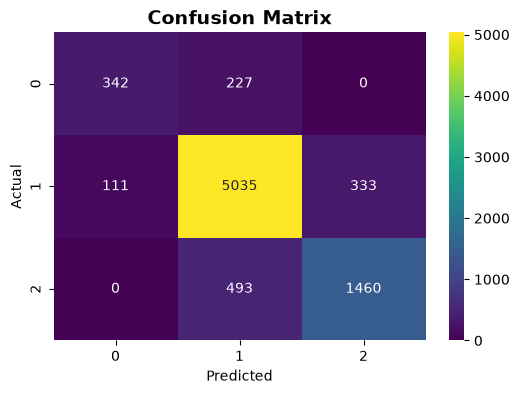

In [61]:
#Creating a Confusion Matrix to check the model's predictions

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix", weight="bold", fontsize=14)
plt.show()

In [62]:
y_proba = model.predict_proba(X_test_st)[:, 1]
y_proba[:10]

array([9.10068707e-01, 3.78906564e-01, 3.73246735e-01, 9.47125900e-01,
       9.22101111e-01, 9.81869048e-01, 9.84033250e-01, 9.85849265e-01,
       6.92234964e-04, 5.82735015e-02])

In [63]:
#Printing a DataFrame comparing the real value with the predicted ones

results = pd.DataFrame({
    'real': y_test,
    'predicted': y_pred,
    'maximum_probability': np.max(y_proba, axis=0)
})
results.head(10)

,real,predicted,maximum_probability
37814,1,1,0.993886
14159,2,2,0.993886
7964,2,2,0.993886
12119,1,1,0.993886
26894,1,1,0.993886
21151,1,1,0.993886
14812,1,1,0.993886
29795,1,1,0.993886
10982,0,0,0.993886
7266,2,2,0.993886
